In [19]:
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path

classifiers = ["logistic_regression","logistic_ridge_regression","logistic_lasso_regression","svm_rbf", "svm_poly", "xgboost","decision_tree","random_forest_default"]
#sim_name = "zeevi_gut_classifier_1"
#sim_name = "brito_oral_classifier_1"
sim_name = "ohj_skin_classifier_1"

for classifier in classifiers:
    filename = f"classification_results/results_{sim_name}_{classifier}.csv"
    if classifier == classifiers[0]:
        result_data = pd.read_csv(filename)
    else:
        result_data = pd.concat([result_data, pd.read_csv(filename)])

#Preprocessing
result_data["Subset Size"] = (
    result_data["Subset"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
)

groups = result_data["Group"].astype(str).unique()

df = result_data.copy()
df.columns = df.columns.str.strip()

metric_cols = ["Accuracy", "Precision", "Recall", "AUROC","Fit Time"]

metric_summary = (
    df.groupby(["Classifier","Group Name", "Subset"])[metric_cols]
    .agg(["mean",stats.sem,lambda x: x.quantile(0.05),lambda x: x.quantile(0.95)]).rename(columns = {'mean': 'mean', 'sem': 'sem', '<lambda_0>': 'quantile_0.05', '<lambda_1>': 'quantile_0.95'})
)

metric_summary=metric_summary.reset_index()

metric_summary["Subset Size"] = (
    metric_summary["Subset"].astype(str).str.extract(r"(\d+)", expand=False).astype(int)
)
scales = metric_summary["Group Name"].astype(str).str.extract(r"ab([\d.]+)prev([\d.]+)")
metric_summary["Ab.scale"] = scales[0].astype(float)
metric_summary["Prev.scale"] = scales[1].astype(float)

#Filtering out values with abundance scales > 10

metric_summary = metric_summary[metric_summary["Ab.scale"] <= 10]

metric_summary




Classifier    Group Name      Subset  Accuracy            \
                                                   mean       sem   
0     decision_tree  ab1.0prev0.0  subset_100  0.496670  0.003364   
1     decision_tree  ab1.0prev0.0  subset_125  0.500224  0.003196   
2     decision_tree  ab1.0prev0.0  subset_150  0.496367  0.002791   
3     decision_tree  ab1.0prev0.0   subset_50  0.491320  0.005320   
4     decision_tree  ab1.0prev0.0   subset_75  0.497733  0.004156   
...             ...           ...         ...       ...       ...   
1435        xgboost  ab7.0prev0.3  subset_100  0.935170  0.003921   
1436        xgboost  ab7.0prev0.3  subset_125  0.924872  0.003656   
1437        xgboost  ab7.0prev0.3  subset_150  0.948067  0.003234   
1438        xgboost  ab7.0prev0.3   subset_50  0.894700  0.006278   
1439        xgboost  ab7.0prev0.3   subset_75  0.886827  0.005180   

                                 Precision                          ...  \
     quantile_0.05 quantile_0.95      mean       sem quantile_0.05  ...   
0         0.438900      0.554050  0.495840  0.003710      0.433366  ...   
1         0.454360      0.550800  0.496421  0.003342      0.445906  ...   
2         0.456633      0.543367  0.496661  0.002940      0.455472  ...   
3         0.407700      0.584100  0.488848  0.006269      0.399750  ...   
4         0.434533      0.580200  0.489676  0.004581      0.419468  ...   
...            ...           ...       ...       ...           ...  ...   
1435      0.844950      0.975050  0.942912  0.003617      0.866111  ...   
1436      0.839000      0.957640  0.932665  0.003879      0.834235  ...   
1437      0.875133      0.976000  0.954196  0.003251      0.871437  ...   
1438      0.762000      0.956100  0.906129  0.005706      0.785447  ...   
1439      0.786133      0.941333  0.896189  0.005122      0.791084  ...   

         AUROC                              Fit Time                          \
           sem quantile_0.05 quantile_0.95      mean       sem quantile_0.05   
0     0.003364      0.438900      0.554050  0.003982  0.000070      0.003670   
1     0.003193      0.454603      0.550619  0.004475  0.000017      0.004218   
2     0.002791      0.456633      0.543367  0.005162  0.000021      0.004835   
3     0.005320      0.407700      0.584100  0.002941  0.000011      0.002781   
4     0.004170      0.434661      0.579491  0.003378  0.000013      0.003162   
...        ...           ...           ...       ...       ...           ...   
1435  0.002310      0.928255      0.997620  0.052304  0.000392      0.048981   
1436  0.002226      0.913942      0.986260  0.058718  0.000390      0.054285   
1437  0.001666      0.942804      0.997071  0.058821  0.000597      0.053396   
1438  0.005213      0.848720      0.991200  0.046470  0.000204      0.044669   
1439  0.003932      0.851214      0.974357  0.051225  0.000257      0.048594   

                   Subset Size Ab.scale Prev.scale  
     quantile_0.95                                  
0         0.004189         100      1.0        0.0  
1         0.004756         125      1.0        0.0  
2         0.005501         150      1.0        0.0  
3         0.003122          50      1.0        0.0  
4         0.003586          75      1.0        0.0  
...            ...         ...      ...        ...  
1435      0.060294         100      7.0        0.3  
1436      0.066195         125      7.0        0.3  
1437      0.070844         150      7.0        0.3  
1438      0.050595          50      7.0        0.3  
1439      0.056267          75      7.0        0.3  

[1120 rows x 26 columns]

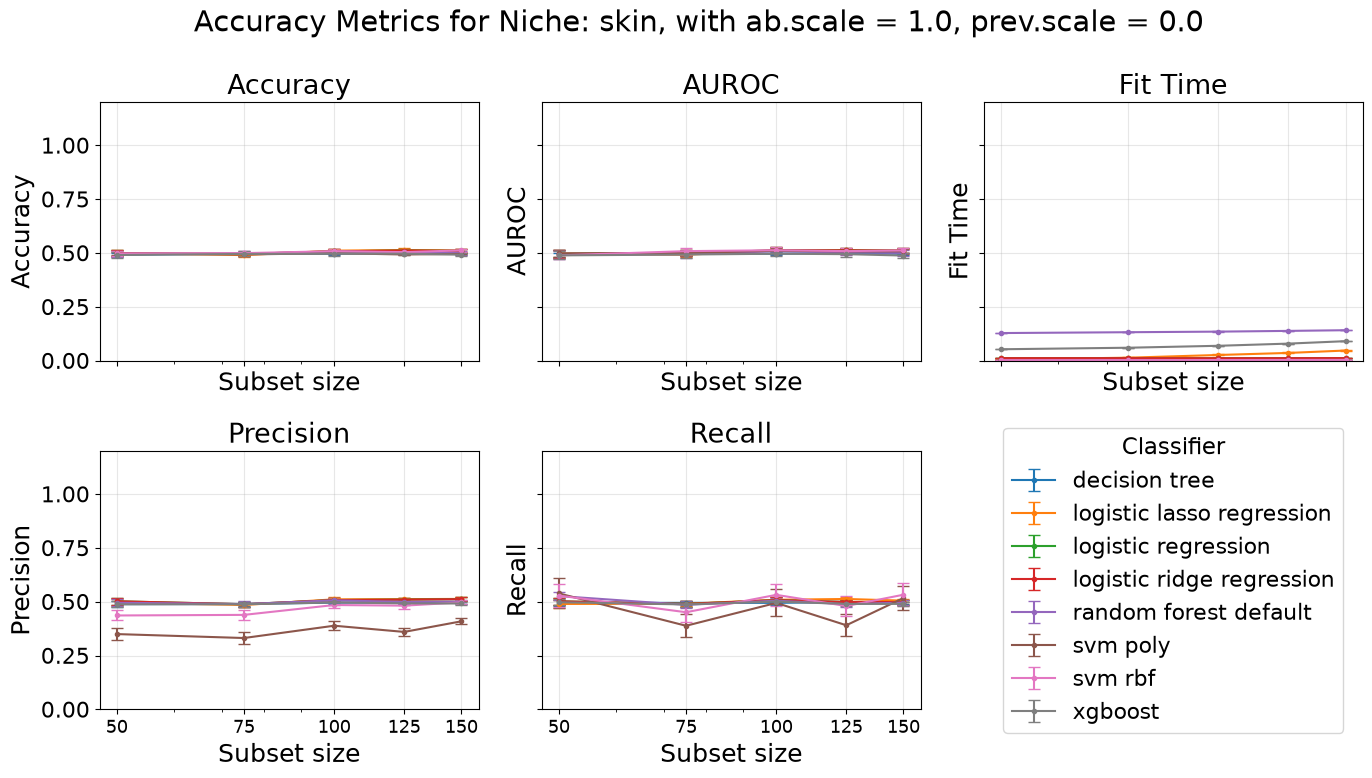

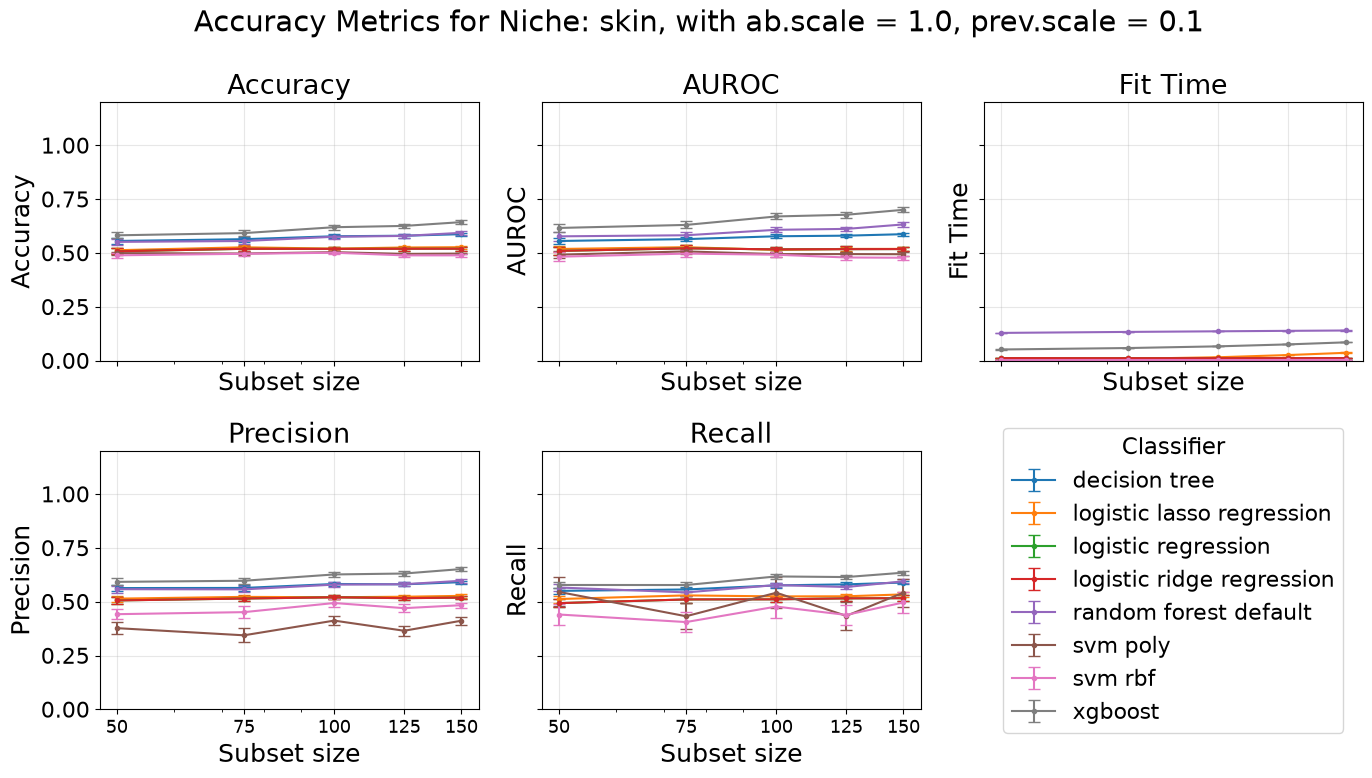

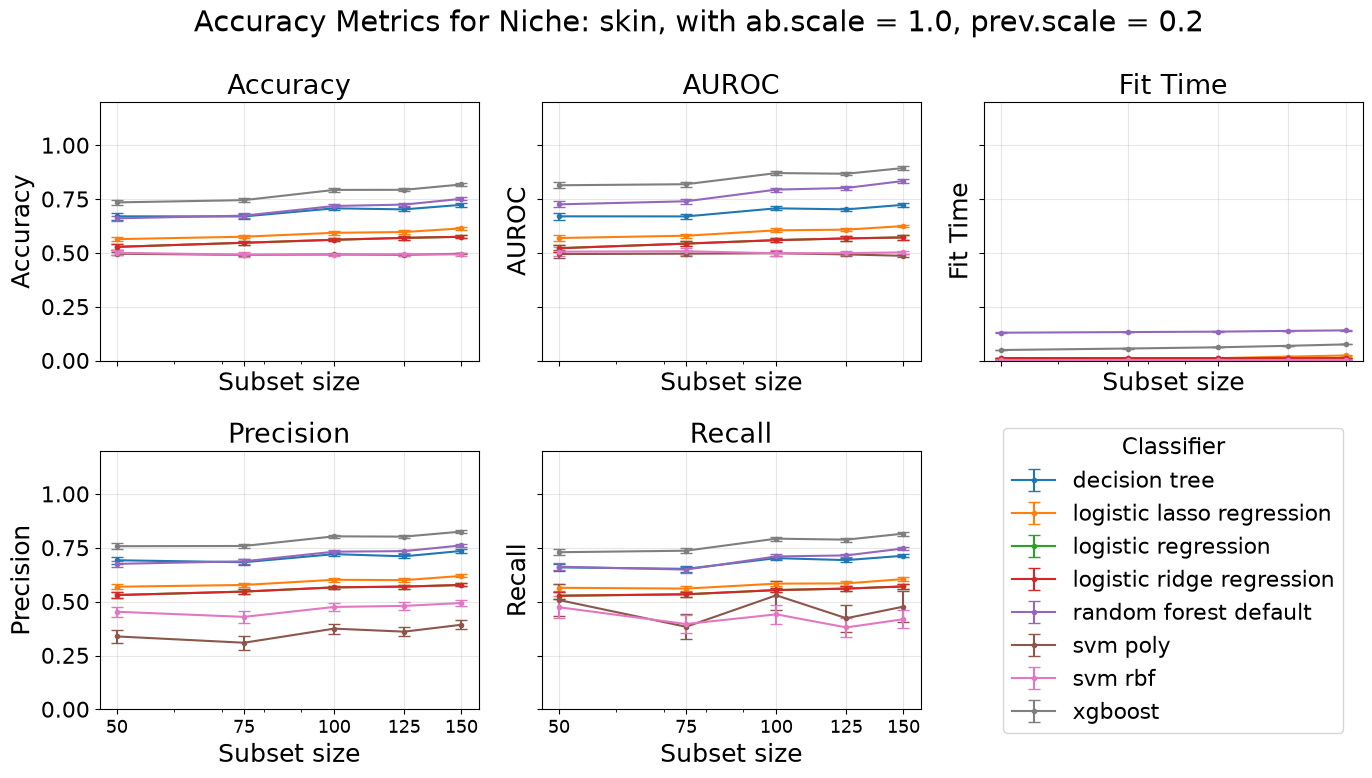

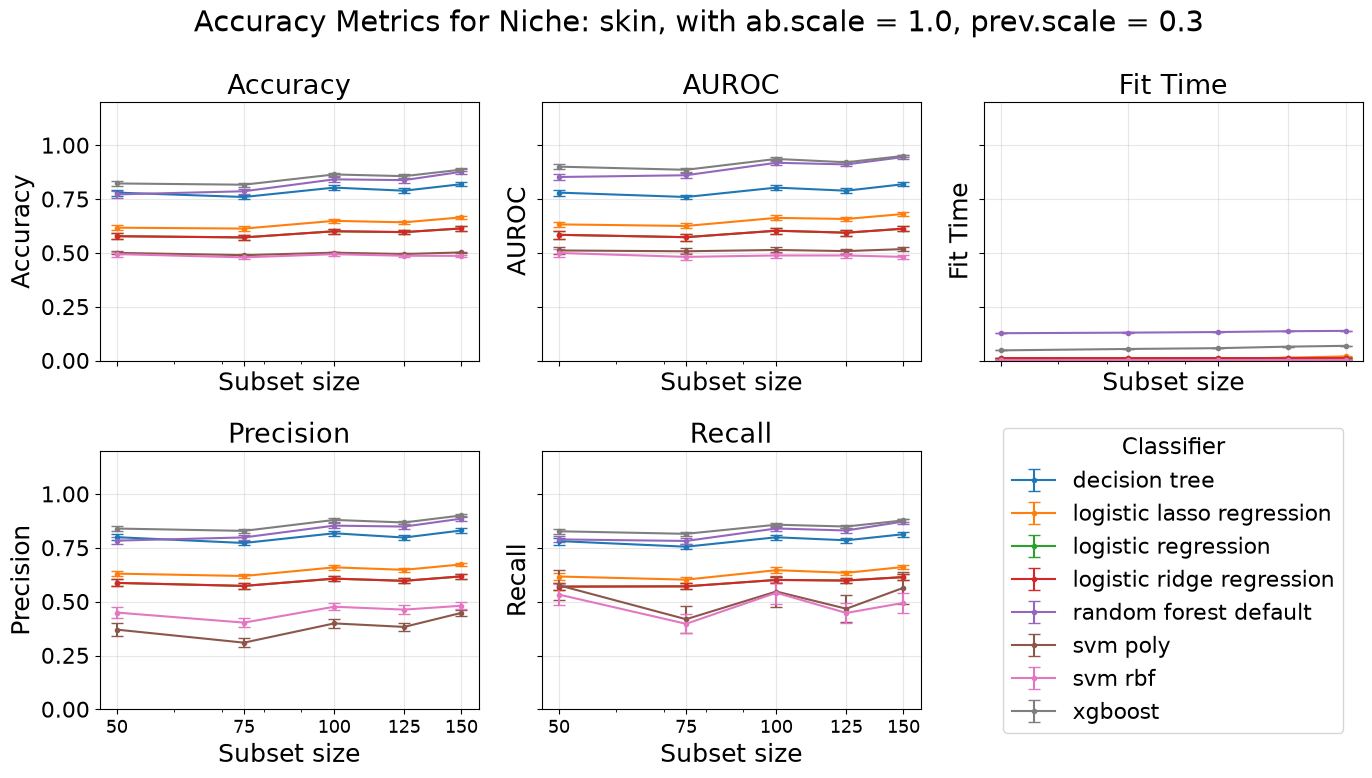

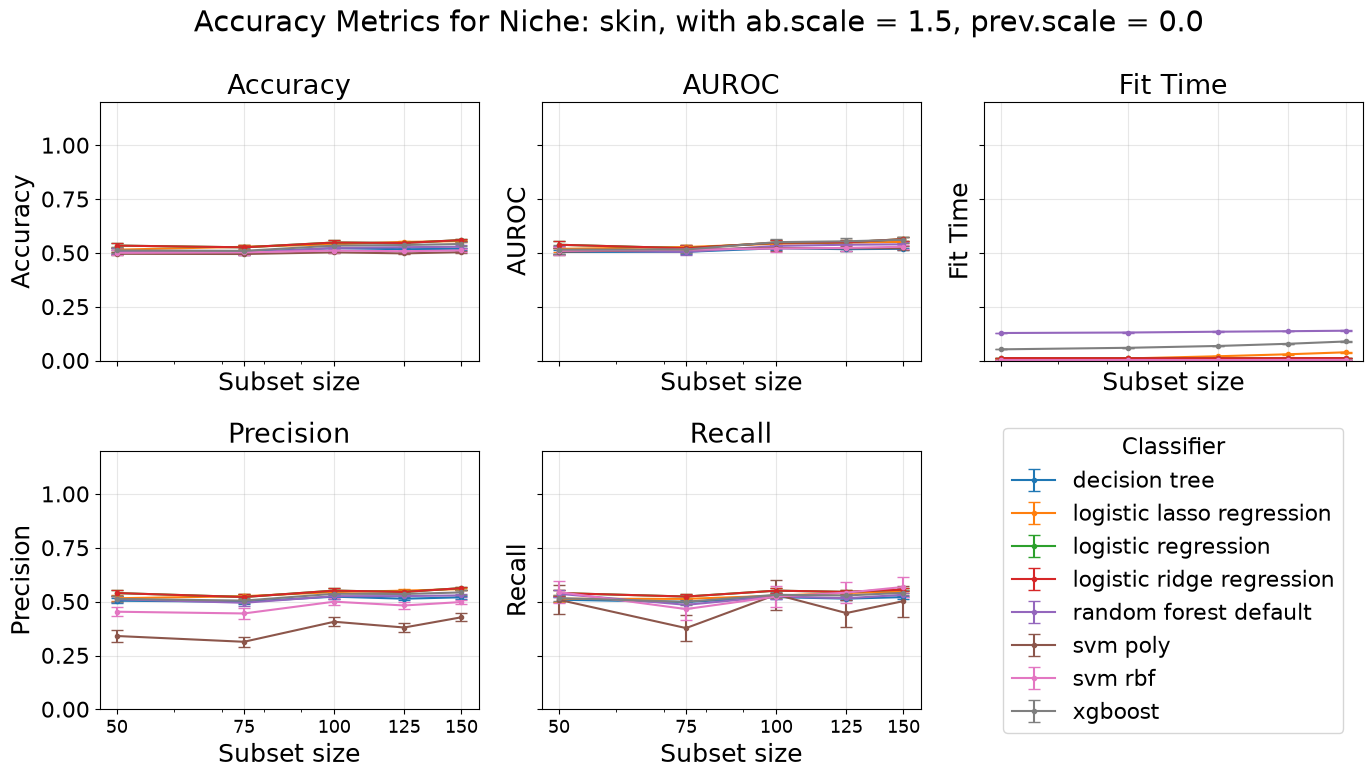

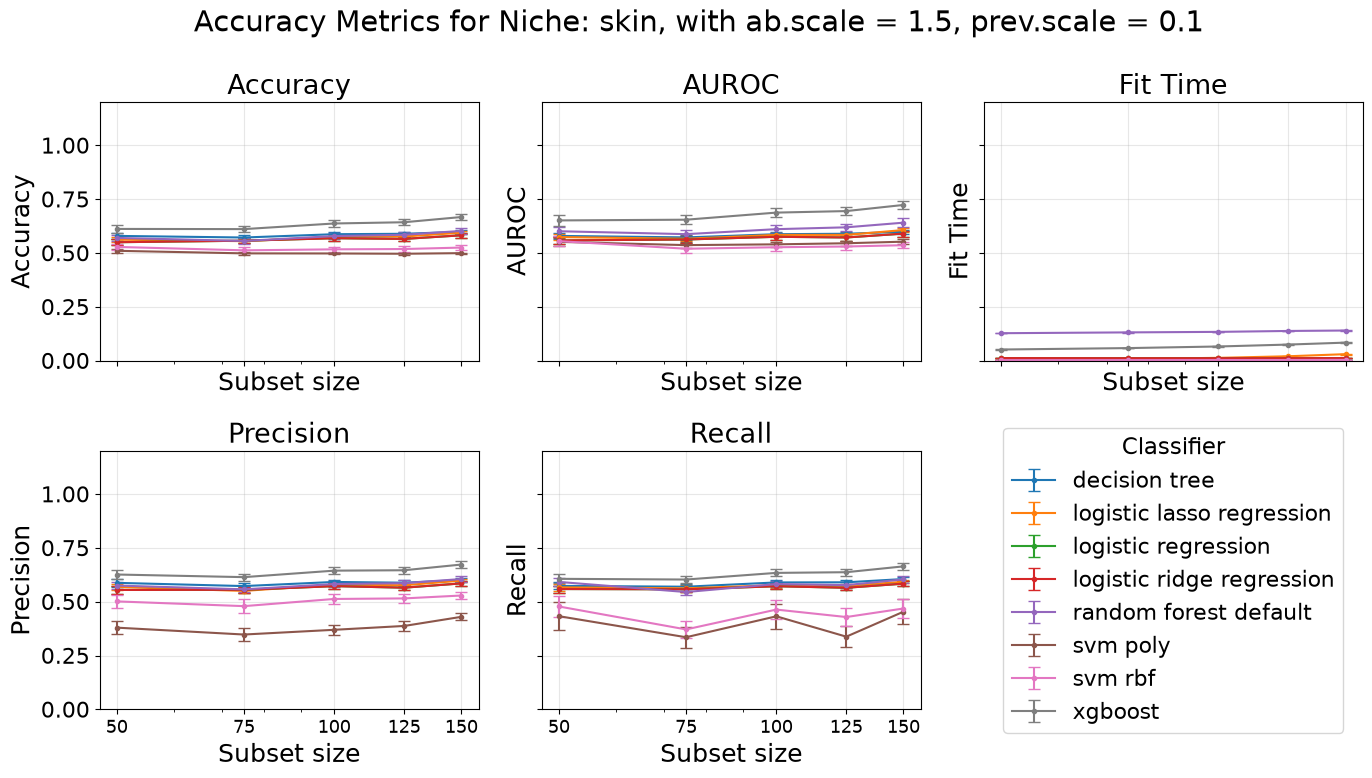

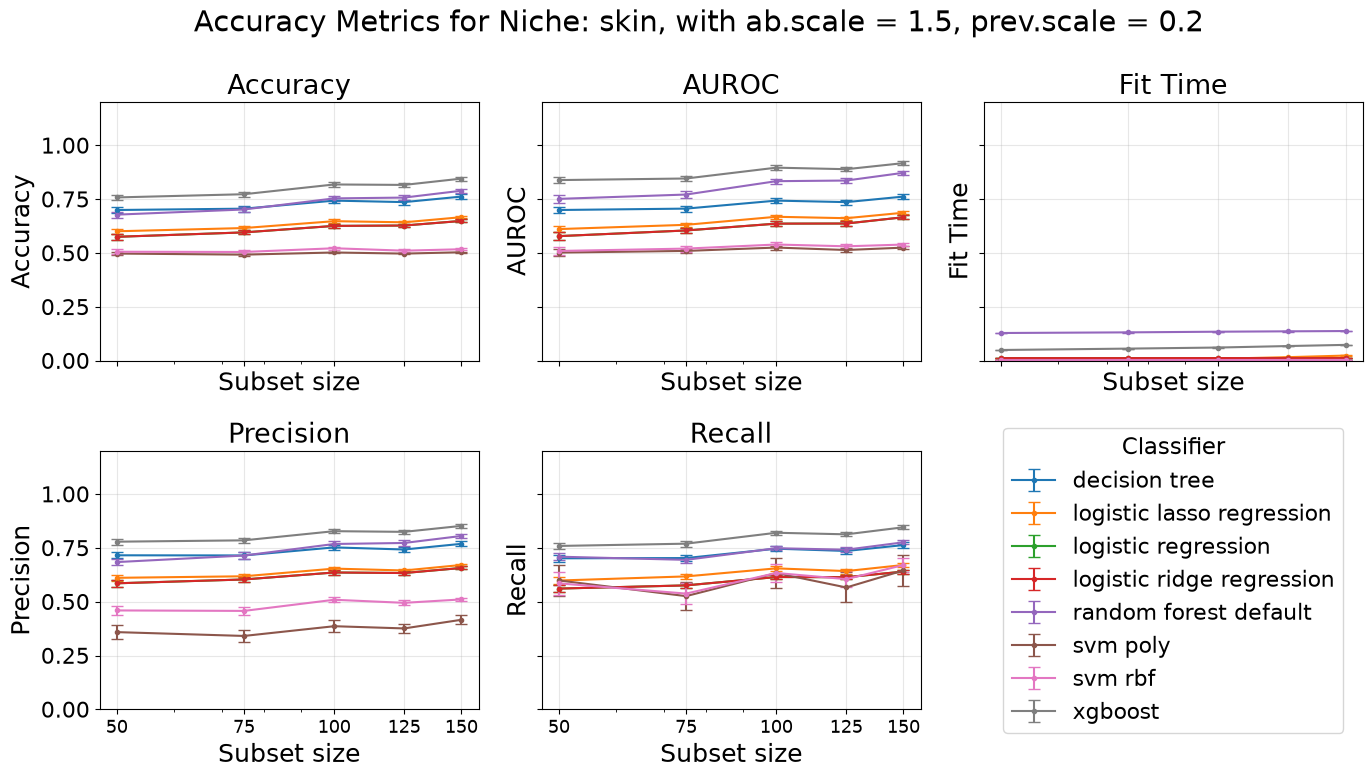

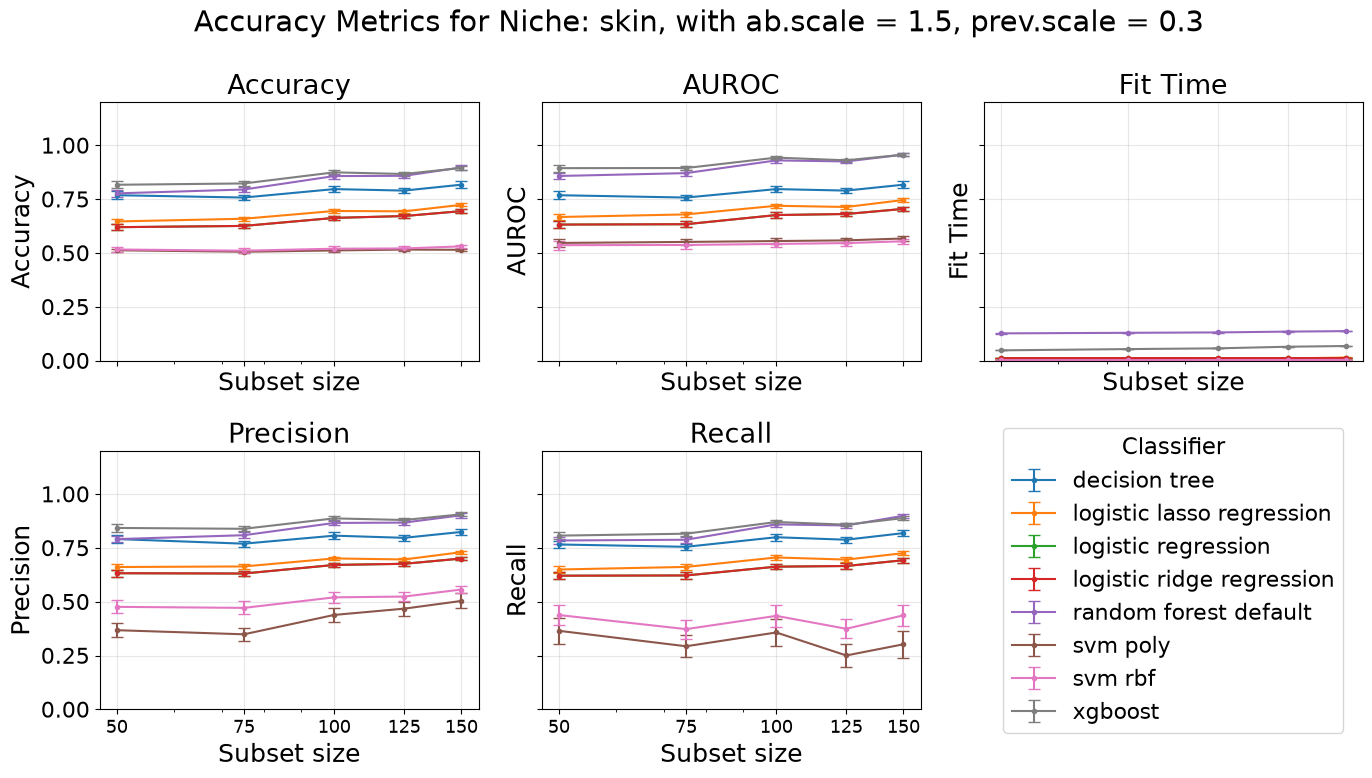

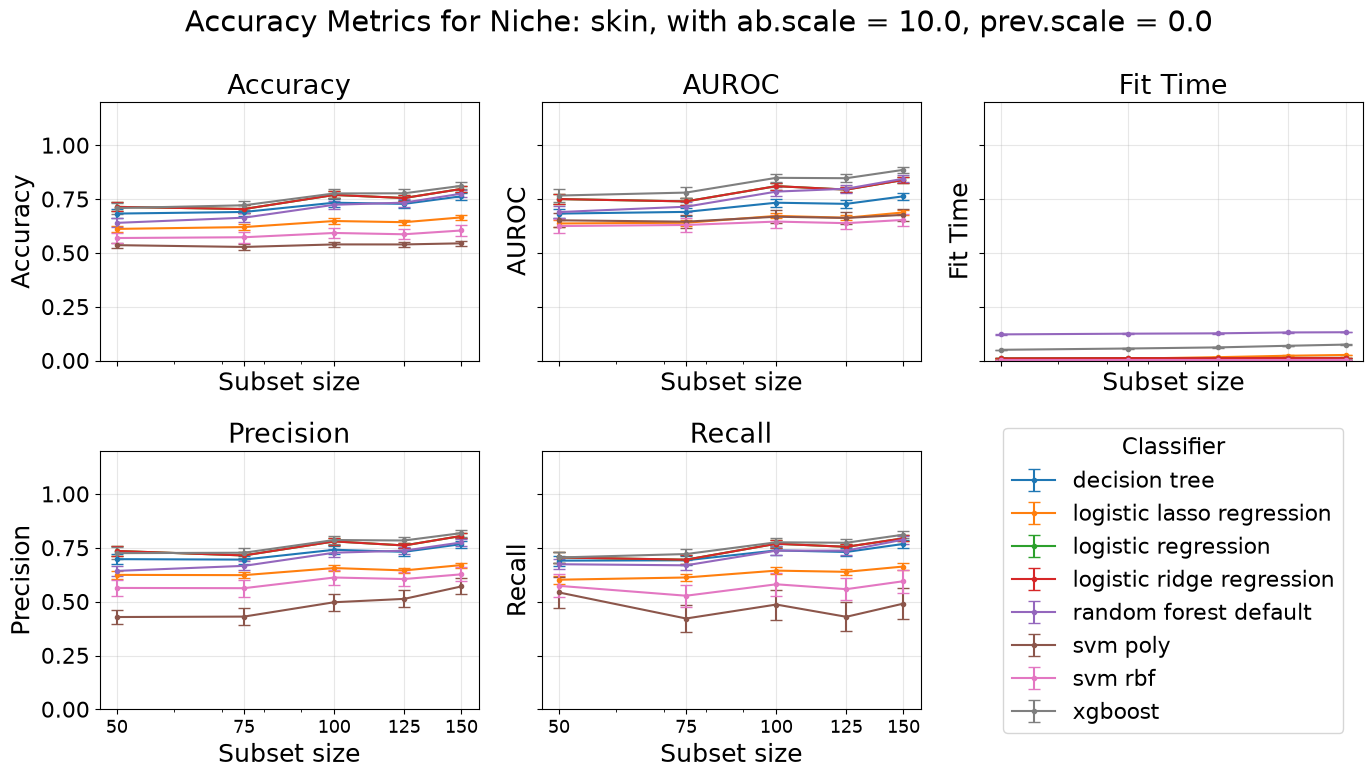

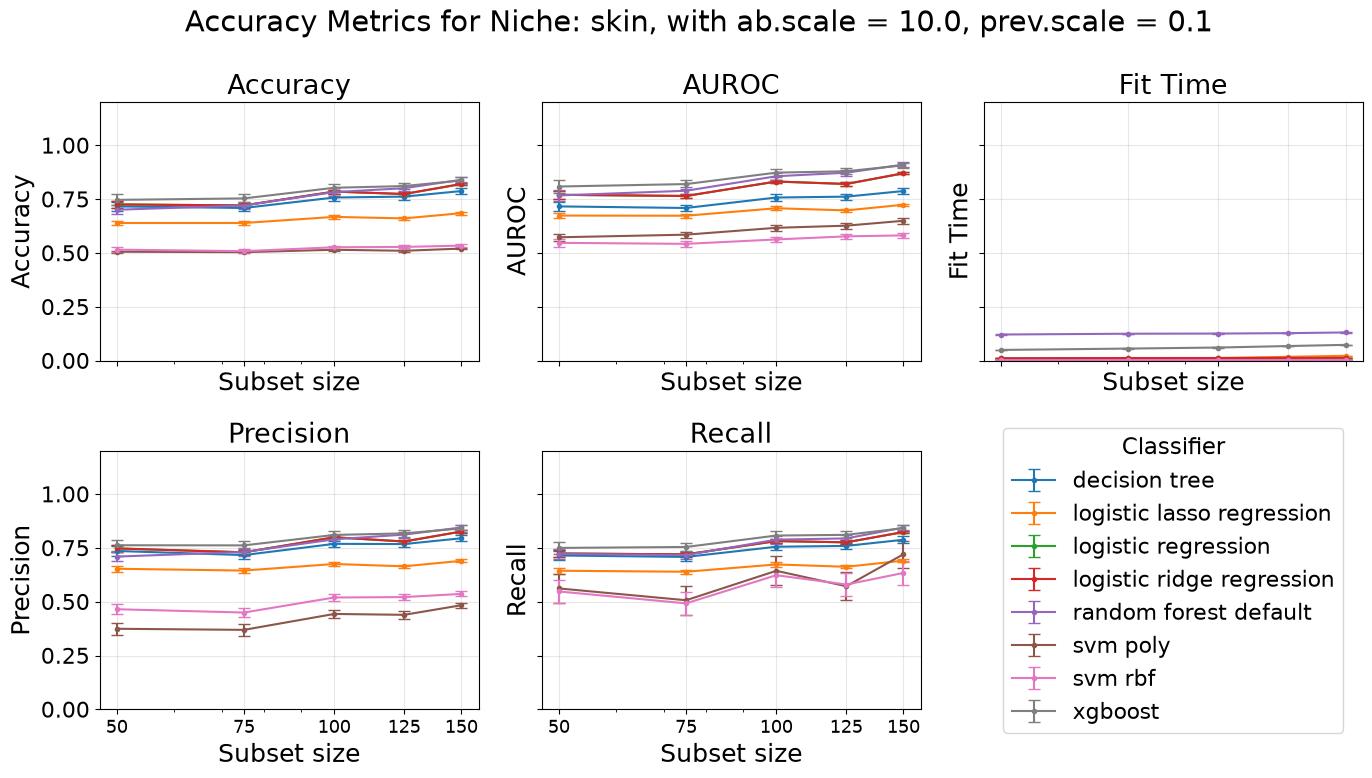

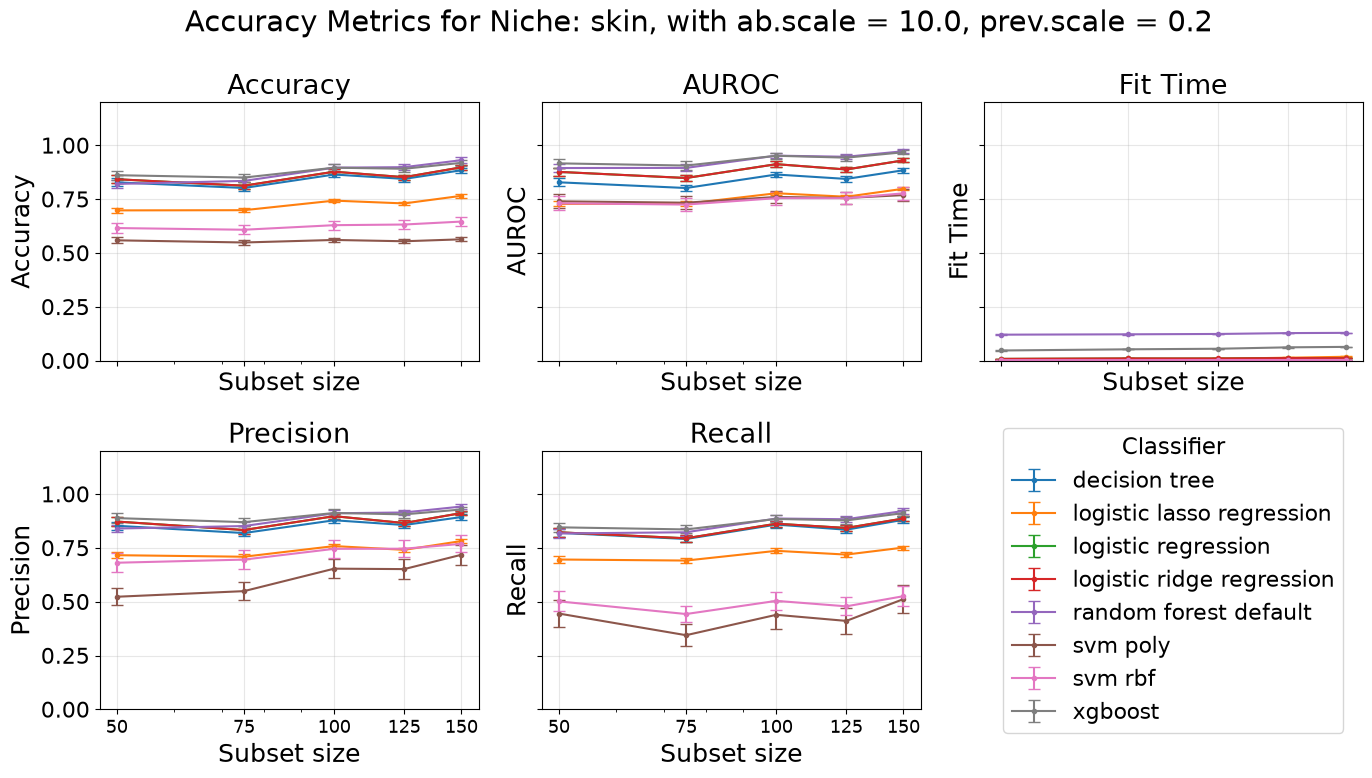

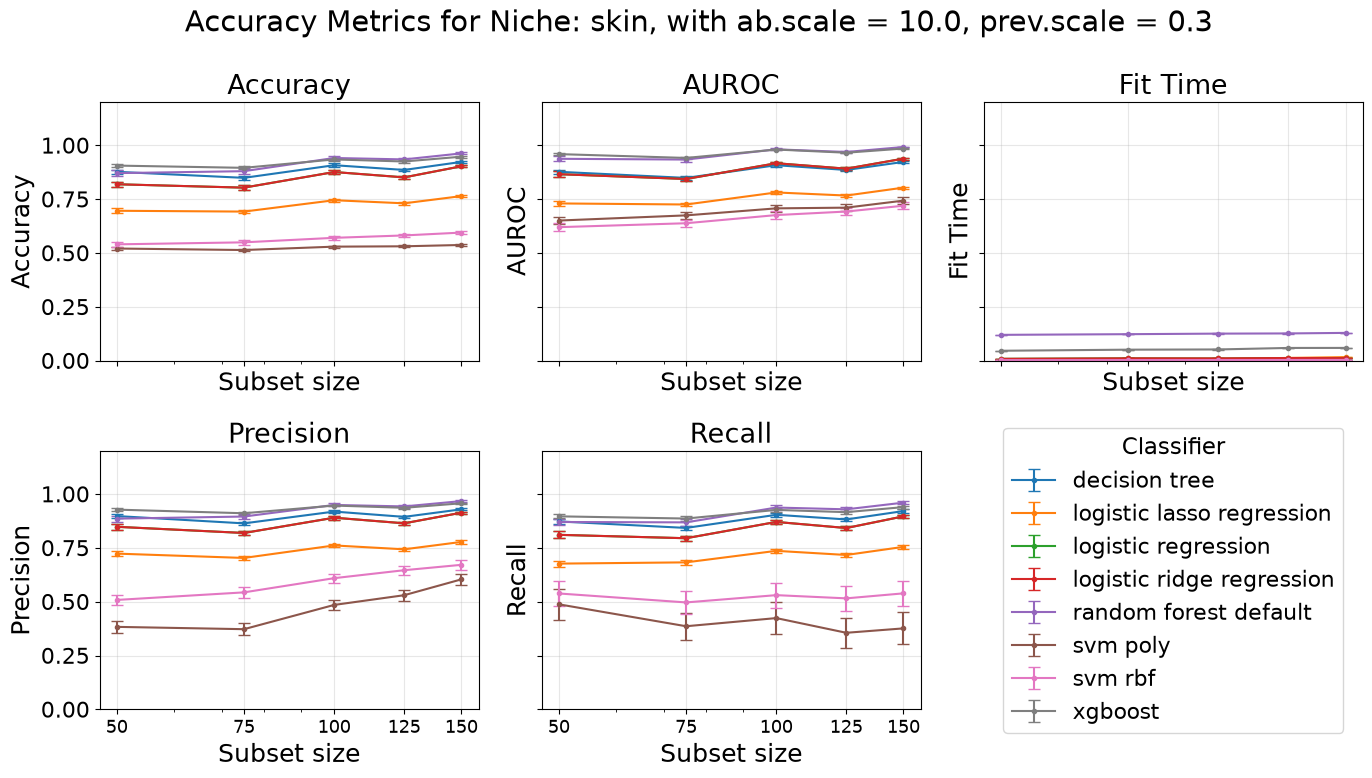

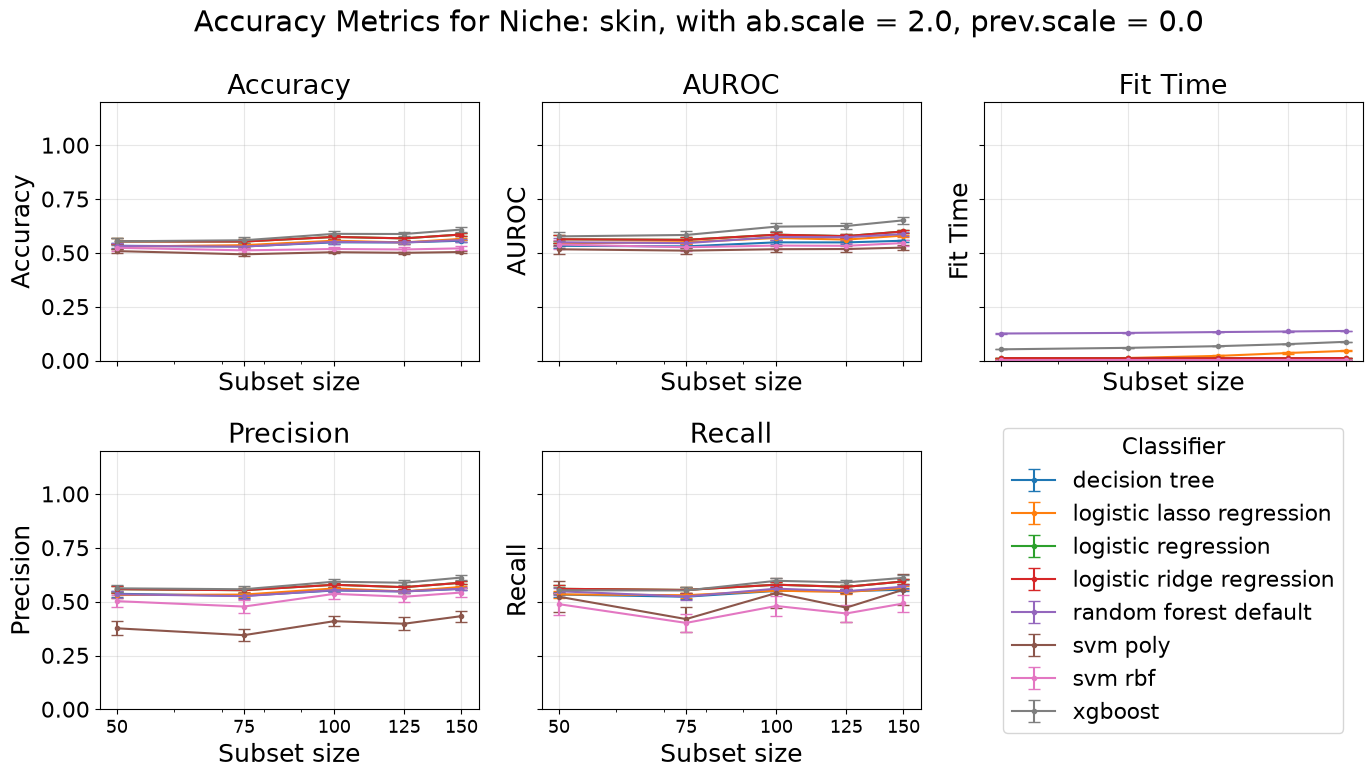

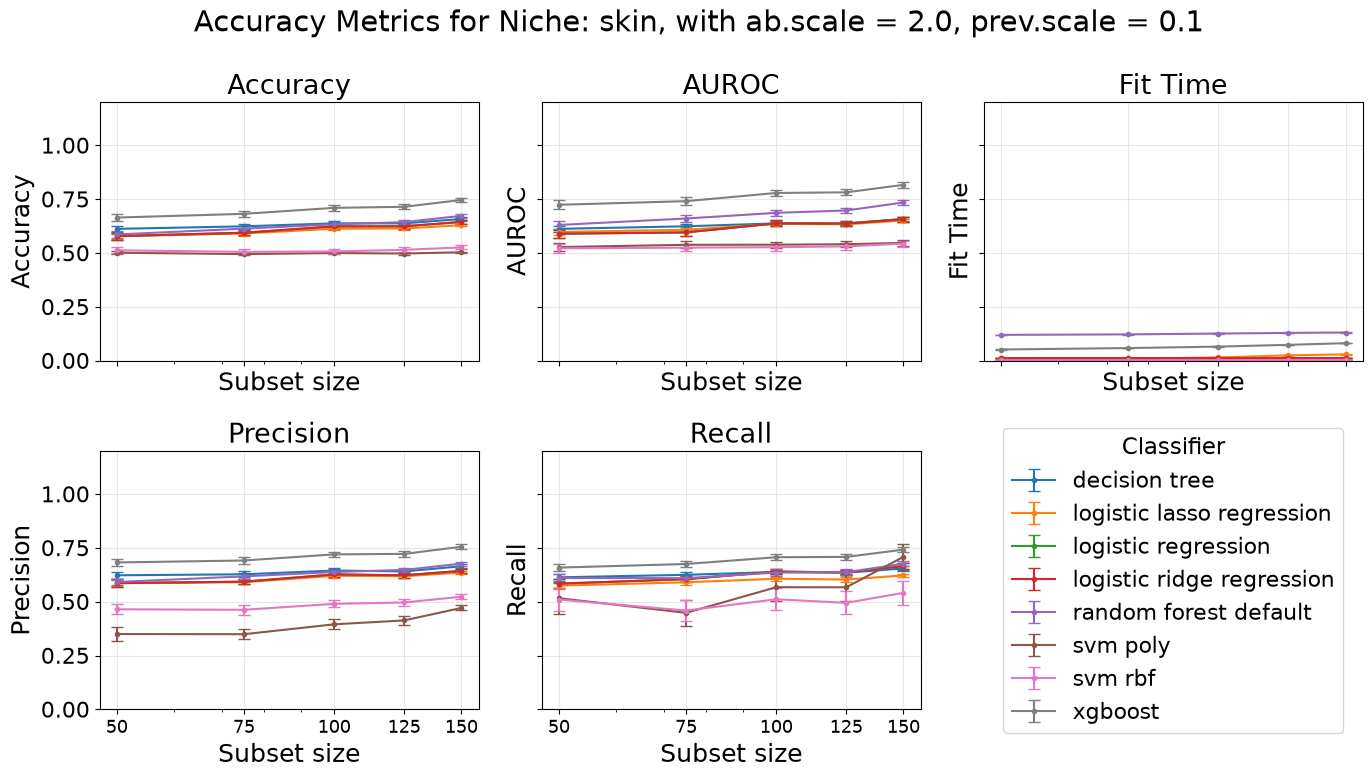

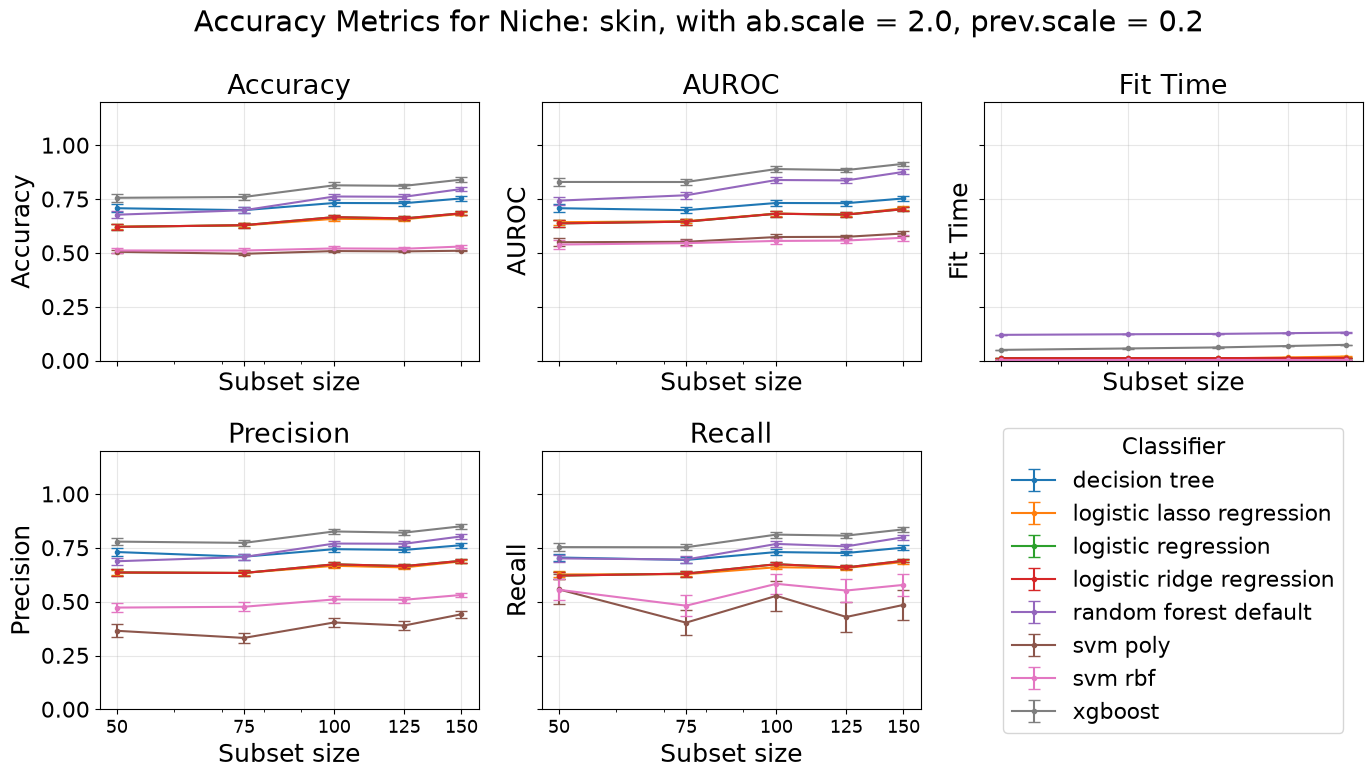

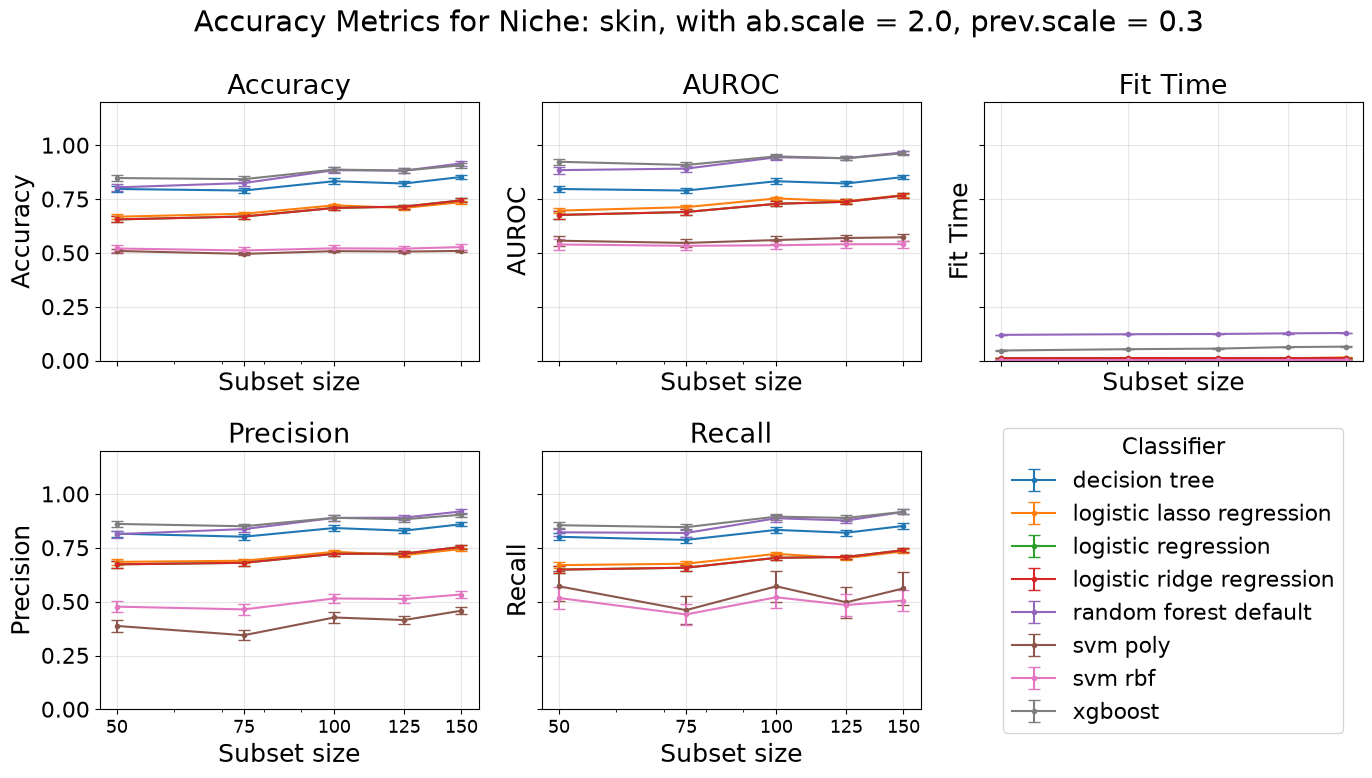

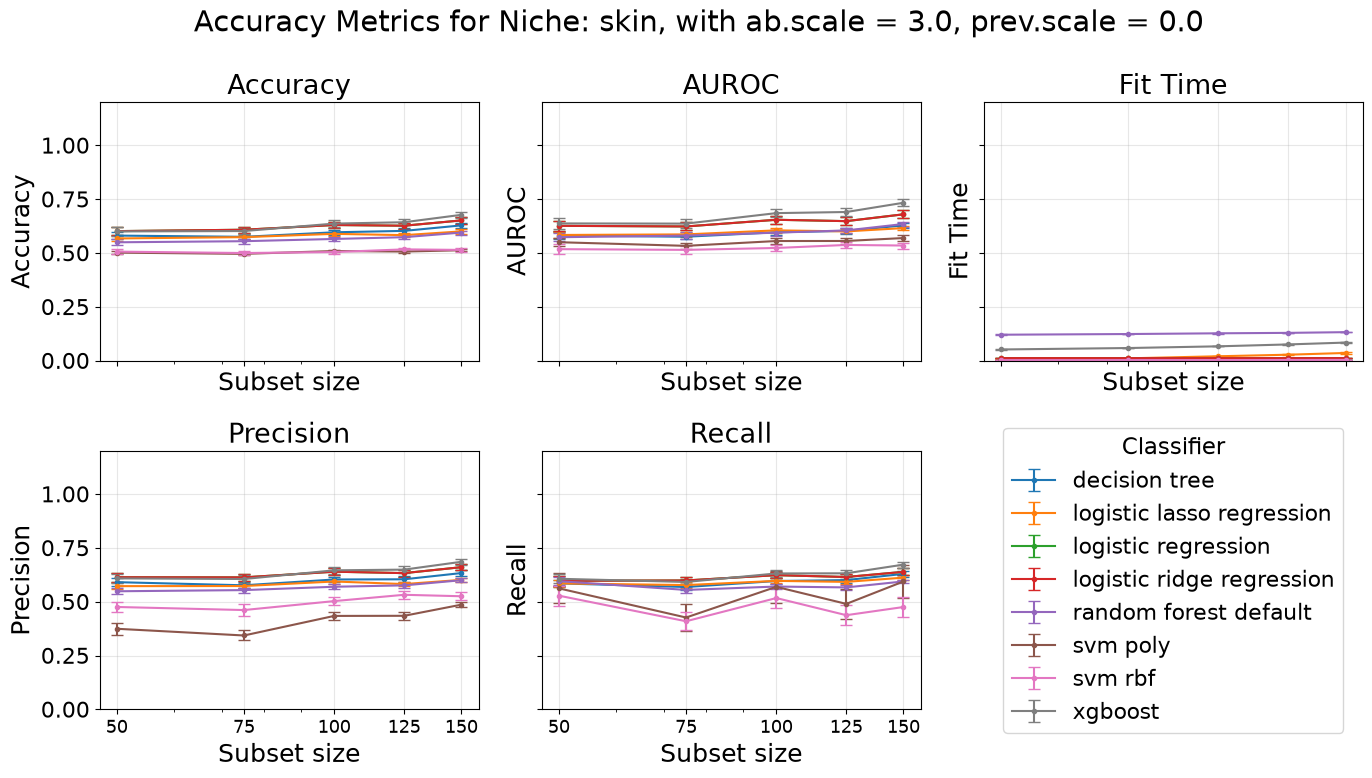

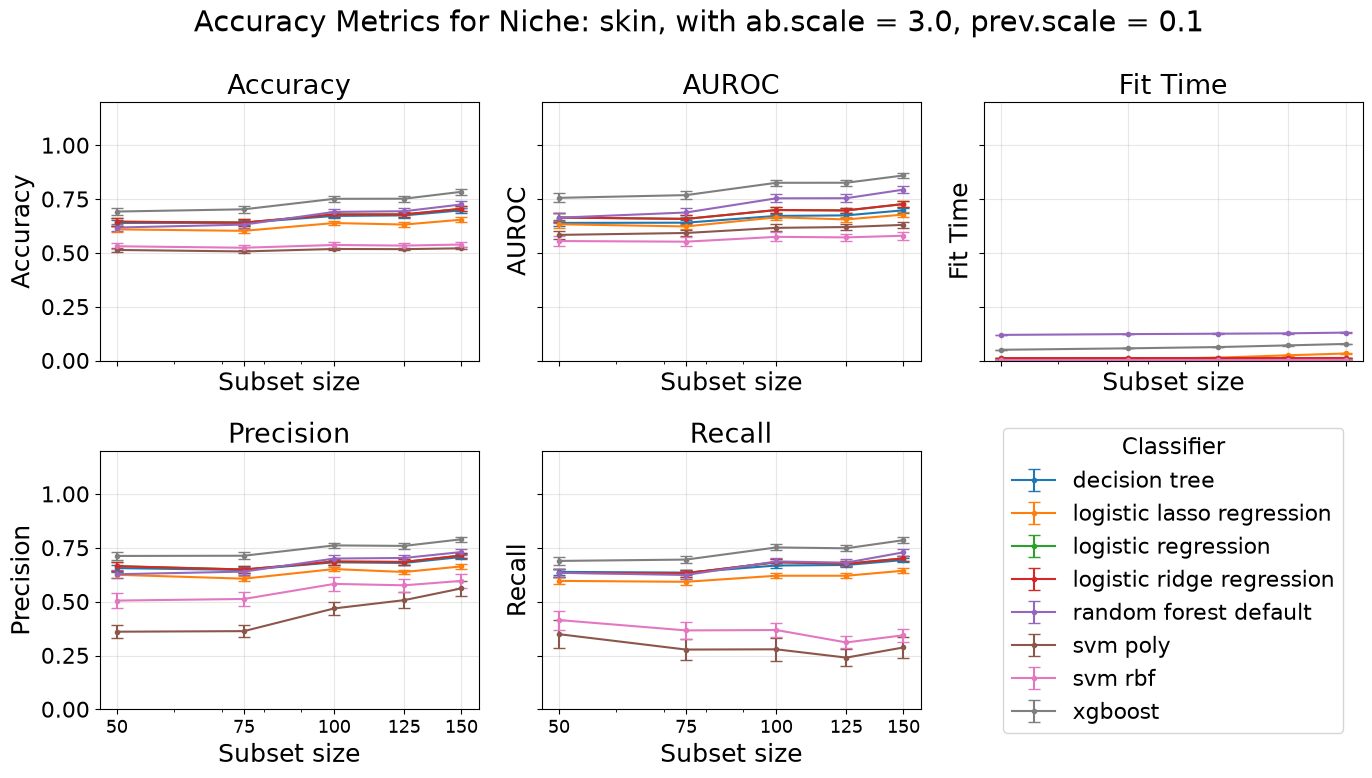

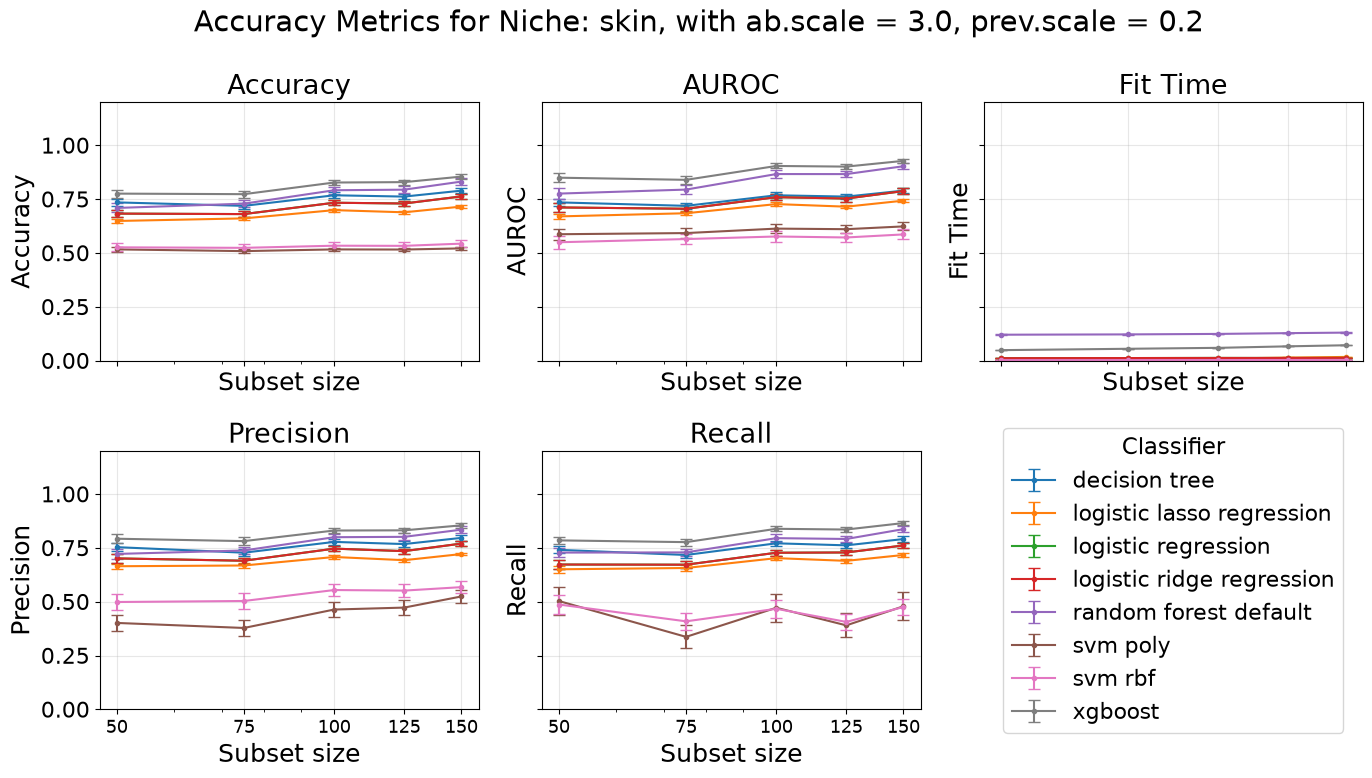

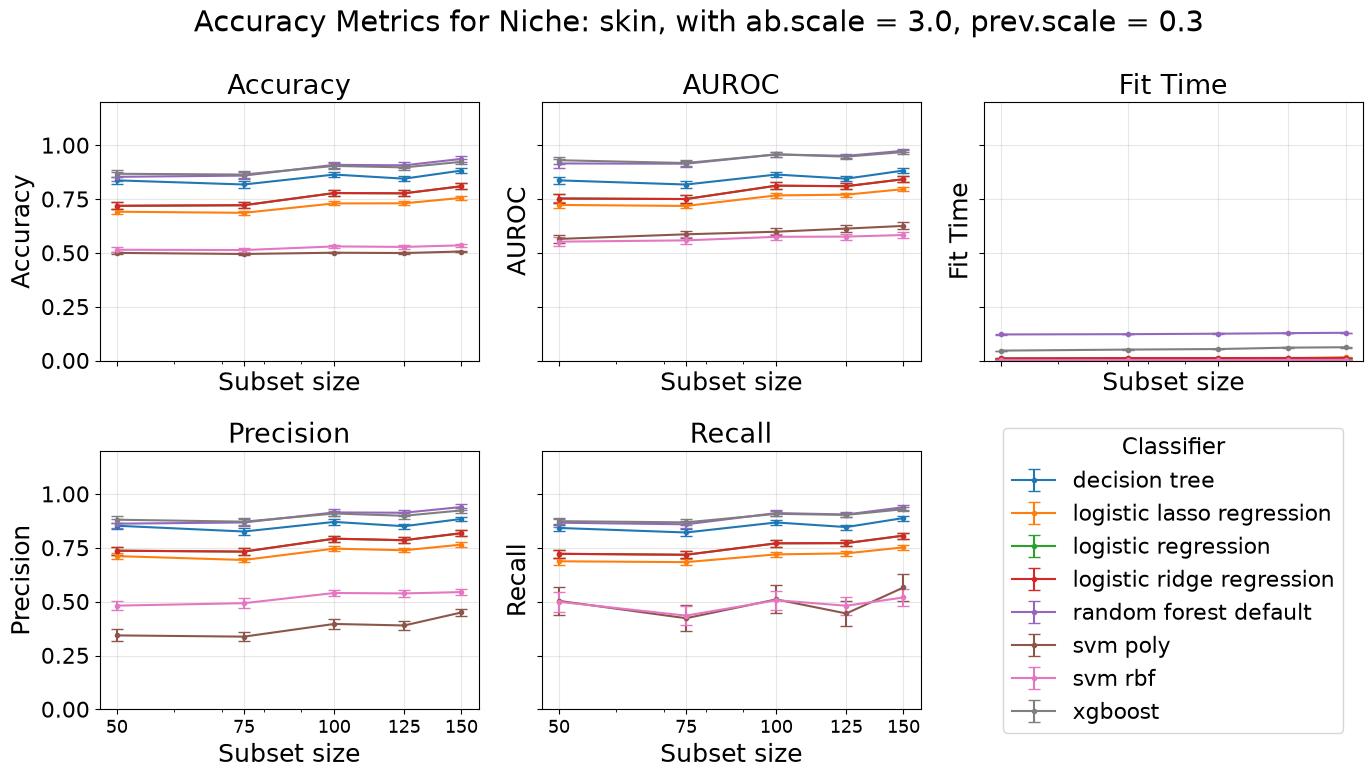

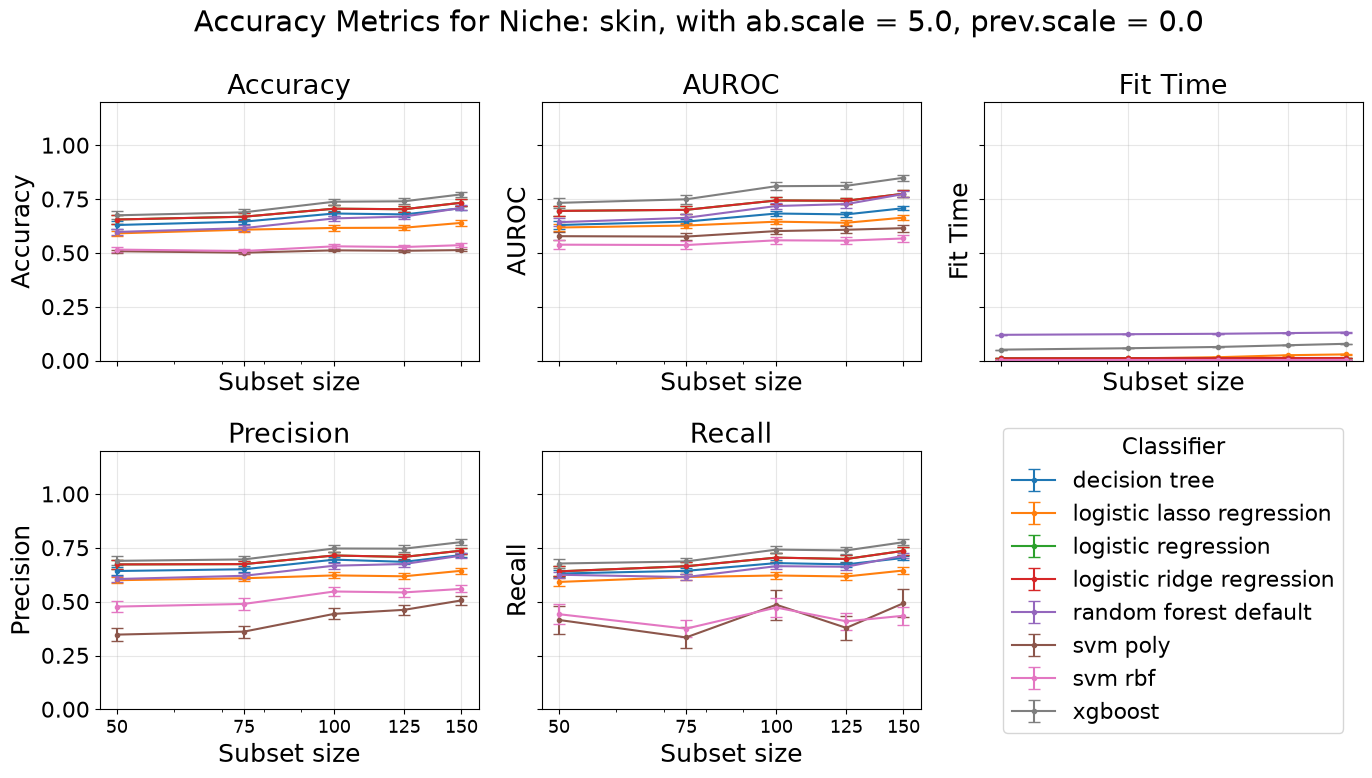

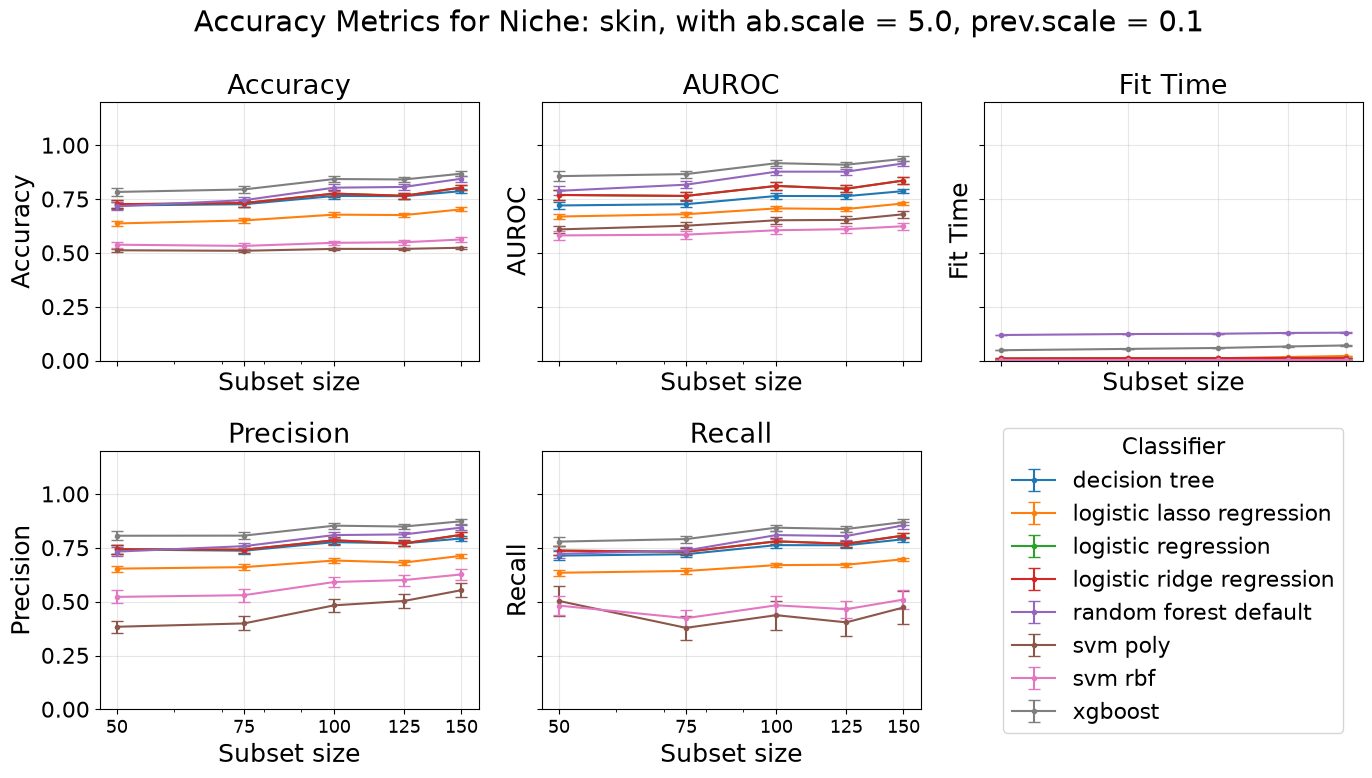

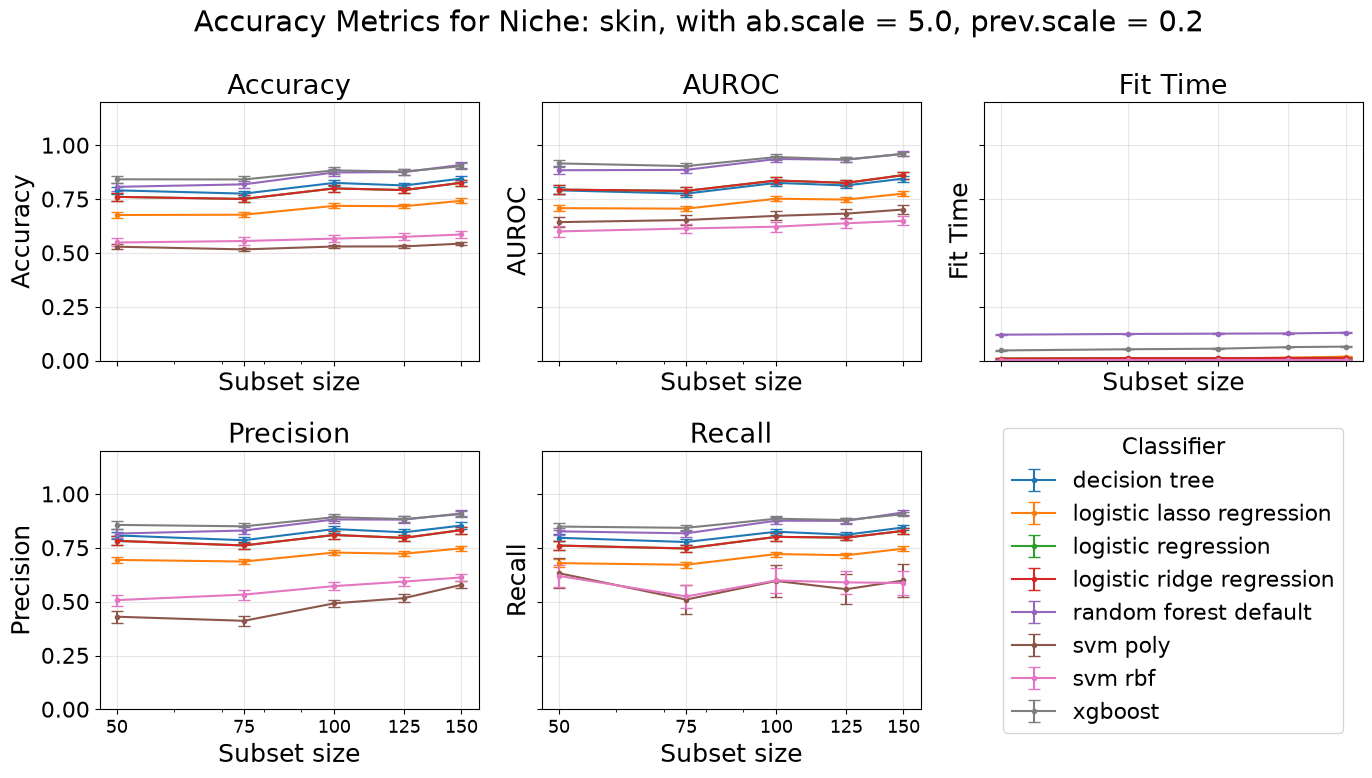

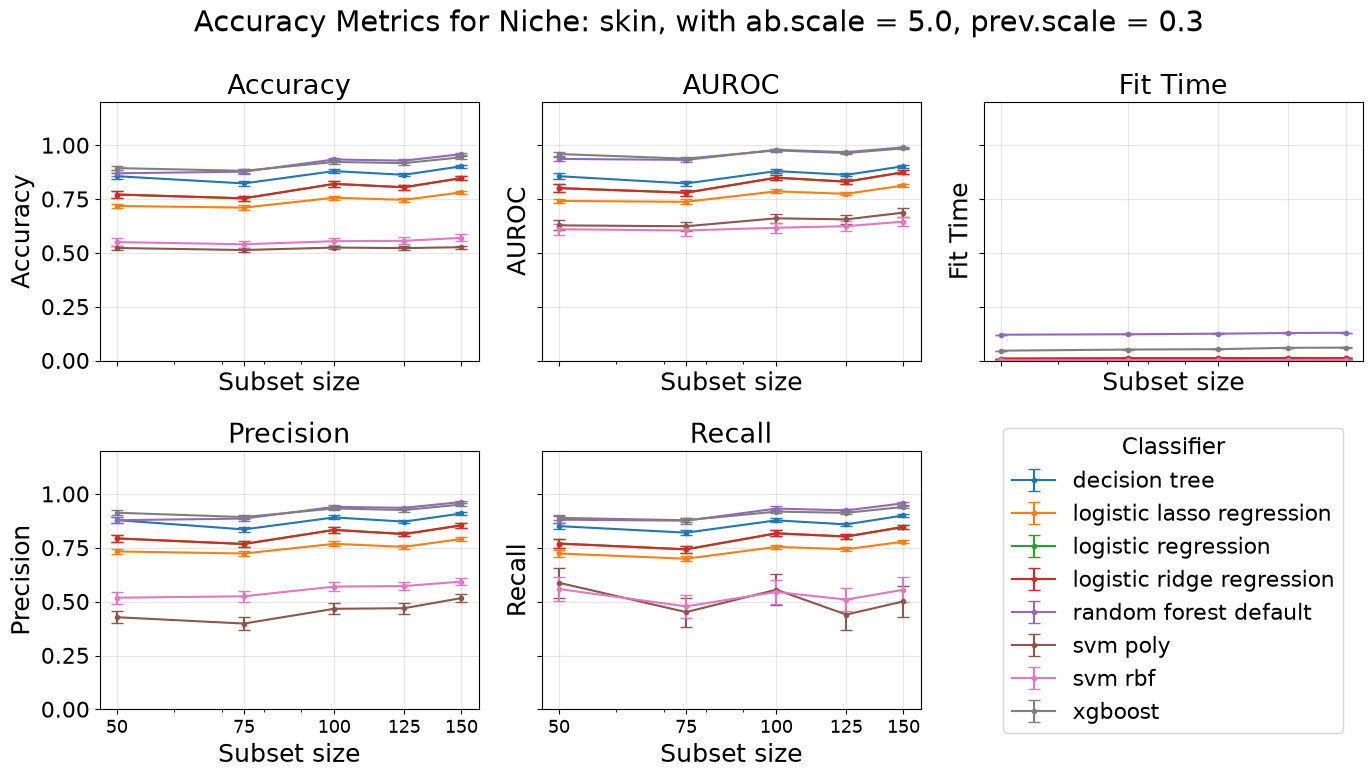

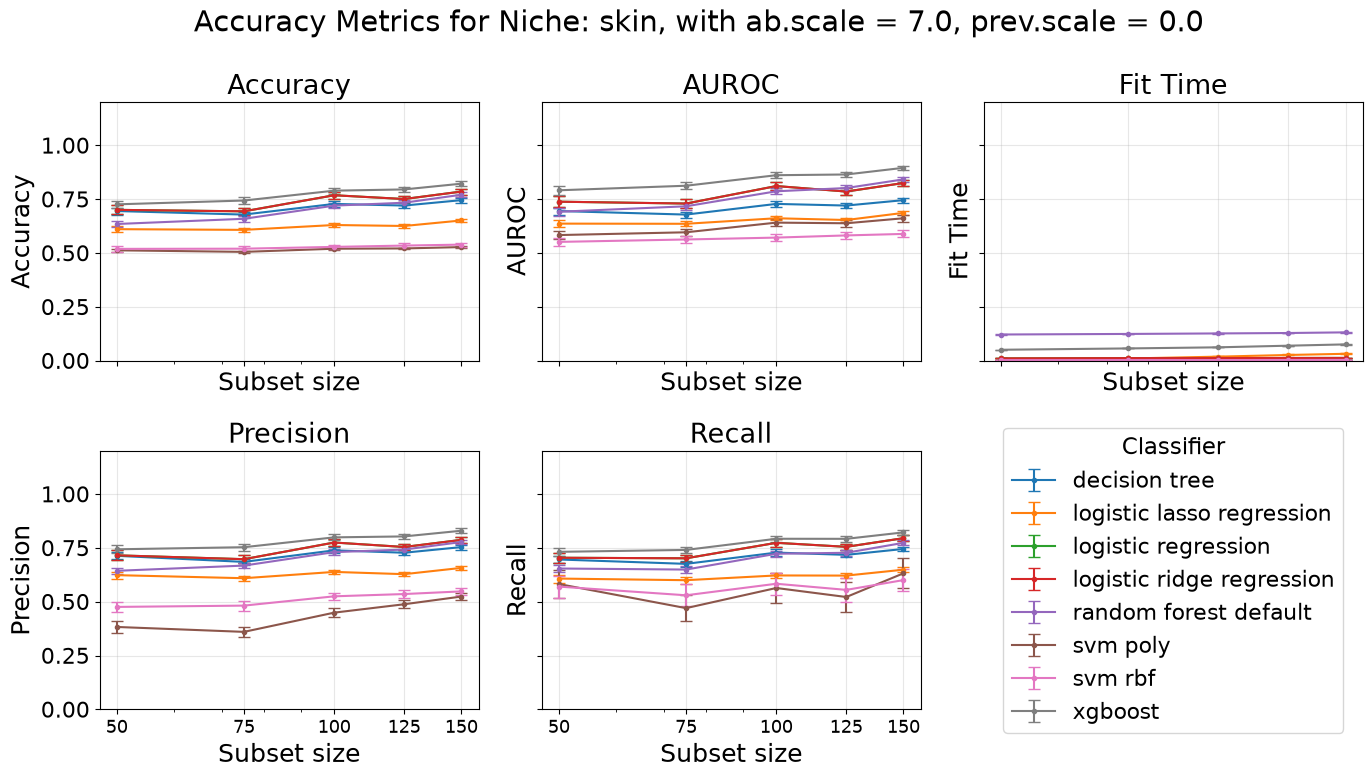

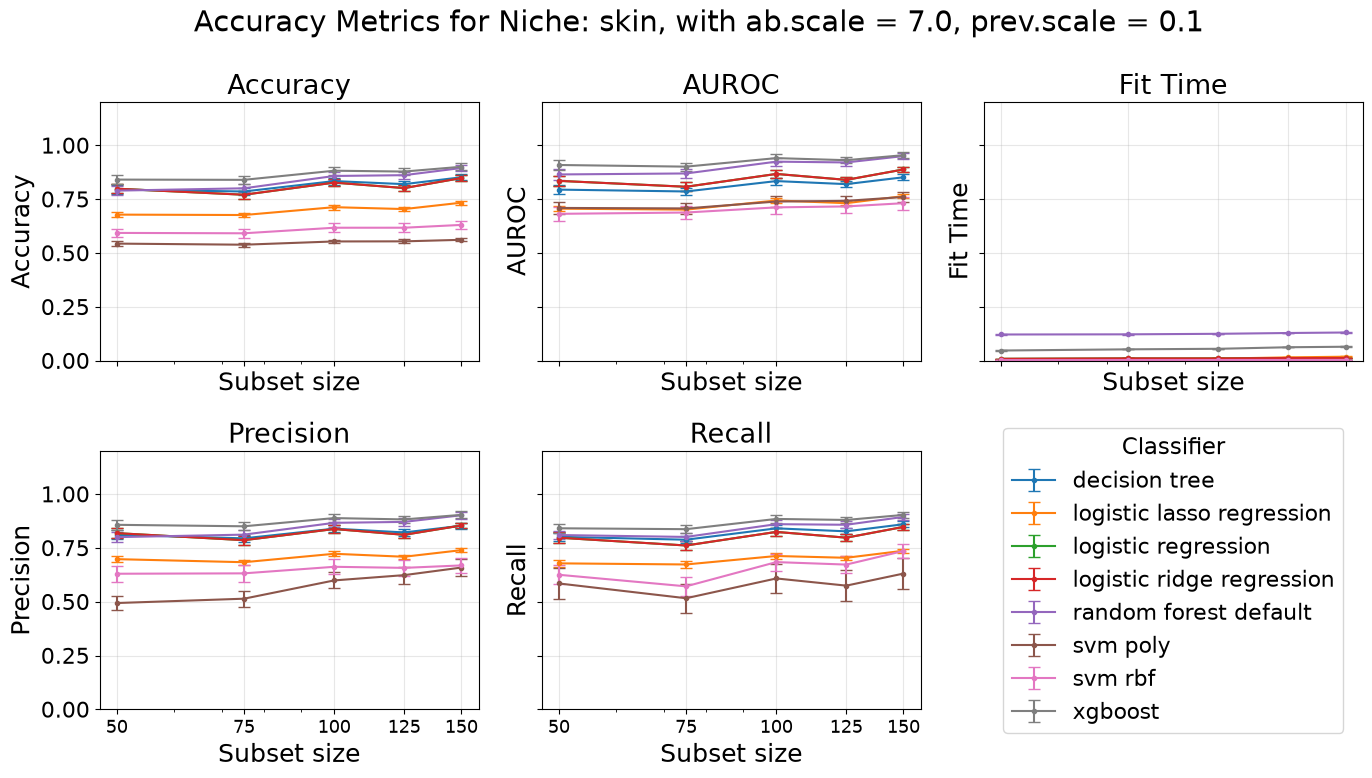

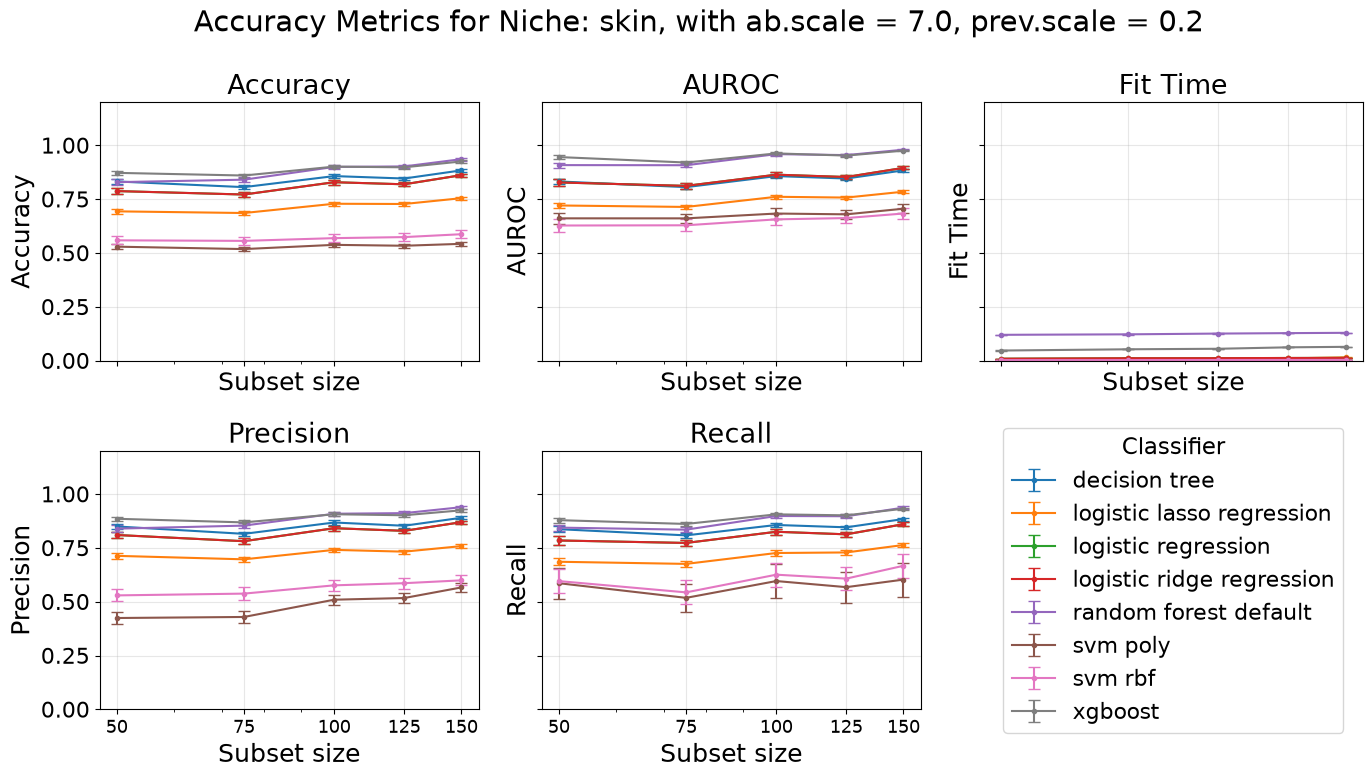

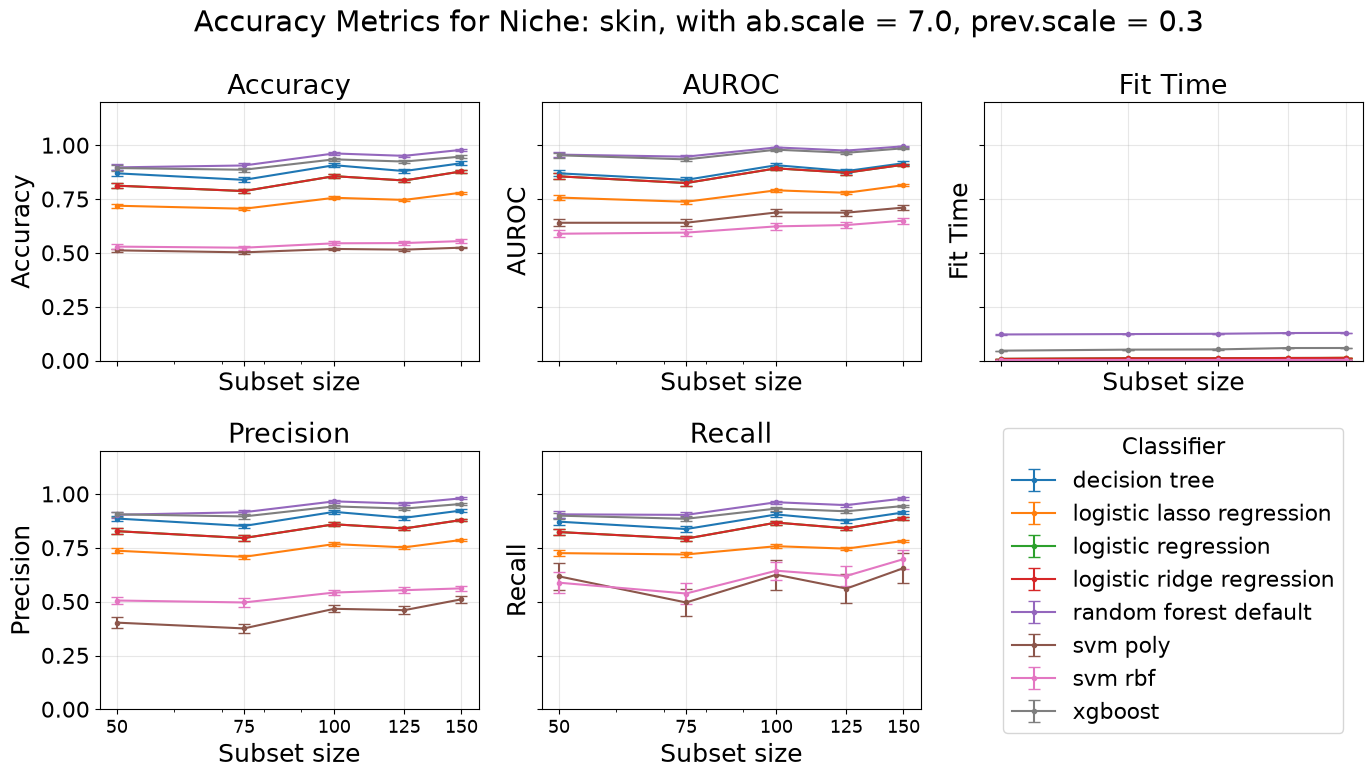

In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter

def pretty_classifier(name):
    return str(name).replace("_", " ")

df = metric_summary.copy()
df = df.sort_values(["Group Name", "Subset Size"])
effects = df["Group Name"].astype(str).unique()

out_dir = Path("classification_plots") / f"{sim_name}" / "metrics_by_effect"
out_dir.mkdir(parents=True, exist_ok=True)

f = 1.3
plot_style = {
    "font.size": 13*f,
    "axes.titlesize": 15*f,
    "axes.labelsize": 14*f,
    "xtick.labelsize": 10*f,
    "ytick.labelsize": 12*f,
    "legend.fontsize": 12*f,
    "legend.title_fontsize": 13*f,
    "figure.titlesize": 16*f,
}

body_site = sim_name.split("_")[1]

with plt.rc_context(plot_style):
    for effect in effects:
        group_df = df[df["Group Name"].astype(str) == effect]
        subset_ticks = sorted(group_df["Subset Size"].unique())
        subset_labels = [str(int(t)) for t in subset_ticks]

        fig, axes = plt.subplots(
            2, 3,
            figsize=(14, 8),
            sharex=True,
            sharey=True,
        )

        metric_layout = [
            ["Accuracy", "AUROC", "Fit Time"],
            ["Precision", "Recall", None],
        ]

        for row, metrics in enumerate(metric_layout):
            for col, metric in enumerate(metrics):
                ax = axes[row, col]
                if metric is None:
                    continue
                for classifier, clf_df in group_df.groupby("Classifier", sort=False):
                    clf_df = clf_df.sort_values("Subset Size")
                    ax.errorbar(
                        clf_df["Subset Size"],
                        clf_df[(metric, "mean")],
                        yerr=2 * clf_df[(metric, "sem")],
                        marker="o",
                        ms=3,
                        linewidth=1.5,
                        capsize=4,
                        label=pretty_classifier(classifier),
                    )
                ax.set_title(metric)
                ax.set_xlabel("Subset size")
                ax.set_ylabel(metric)
                ax.grid(True, alpha=0.3)
                ax.set_ylim(0, 1.2)
                ax.set_xscale("log")
                ax.xaxis.set_major_locator(FixedLocator(subset_ticks))
                ax.xaxis.set_major_formatter(FixedFormatter(subset_labels))
                ax.xaxis.set_minor_formatter(NullFormatter())

        handles, labels = axes[0, 0].get_legend_handles_labels()
        legend_ax = axes[1, 2]
        legend_ax.axis("off")
        legend_ax.legend(handles, labels, title="Classifier", loc="center")

        ab = float(effect.split("prev")[0].removeprefix("ab"))
        prev = float(effect.split("prev")[1])

        fig.suptitle(f"Accuracy Metrics for Niche: {body_site}, with ab.scale = {ab}, prev.scale = {prev}")
        fig.tight_layout()
        for ax in axes.ravel():
            if ax is legend_ax:
                continue
            ax.xaxis.set_major_locator(FixedLocator(subset_ticks))
            ax.xaxis.set_major_formatter(FixedFormatter(subset_labels))
            ax.xaxis.set_minor_formatter(NullFormatter())
        plt.show()

        fig.savefig(out_dir / f"{effect}.png", dpi=200, bbox_inches="tight")

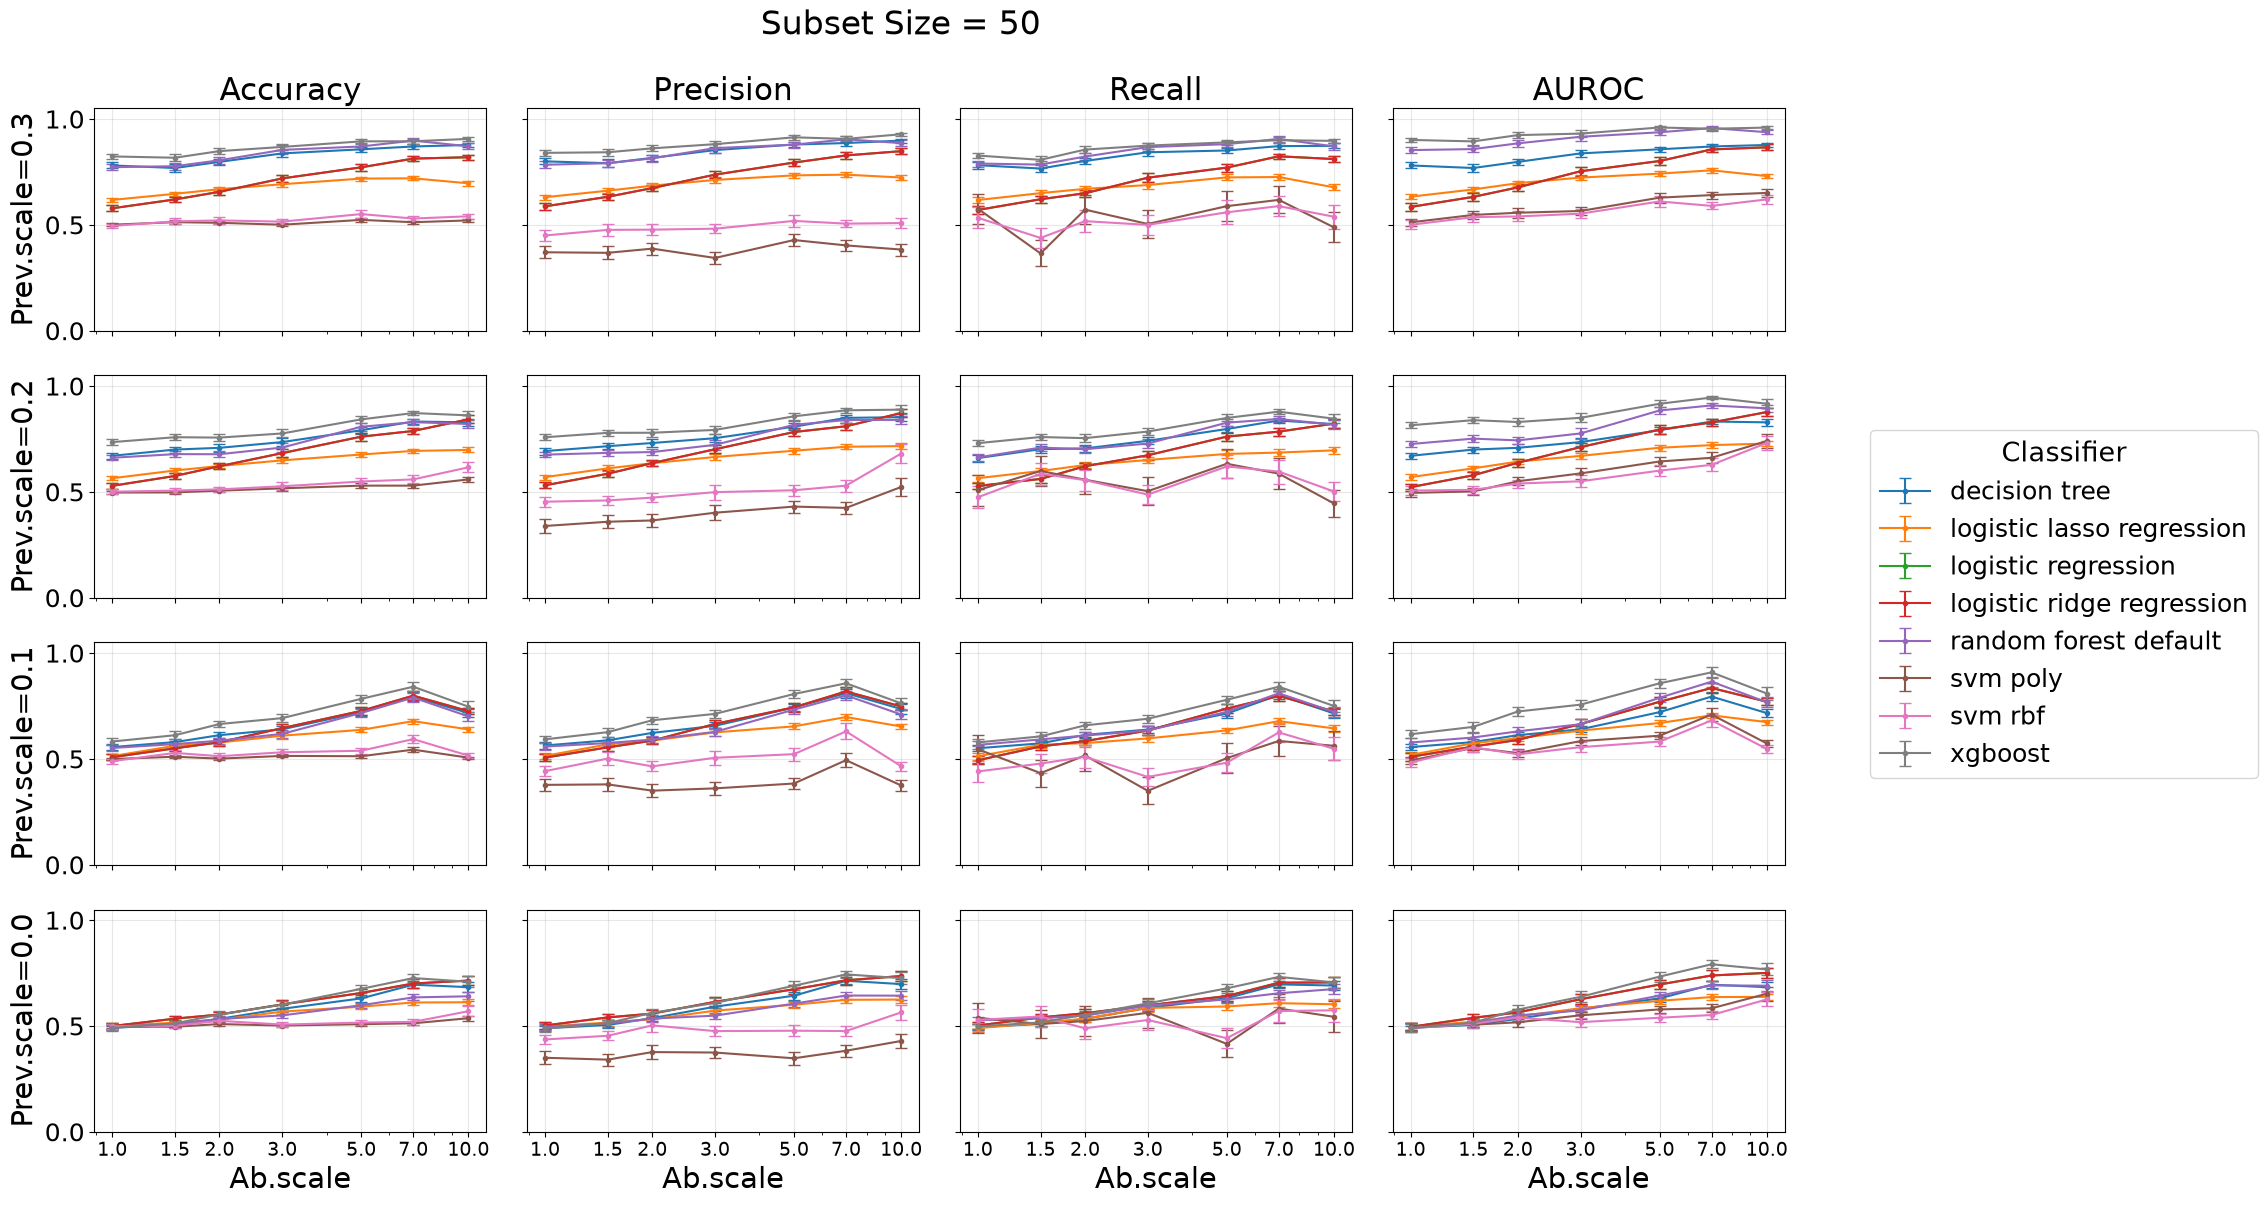

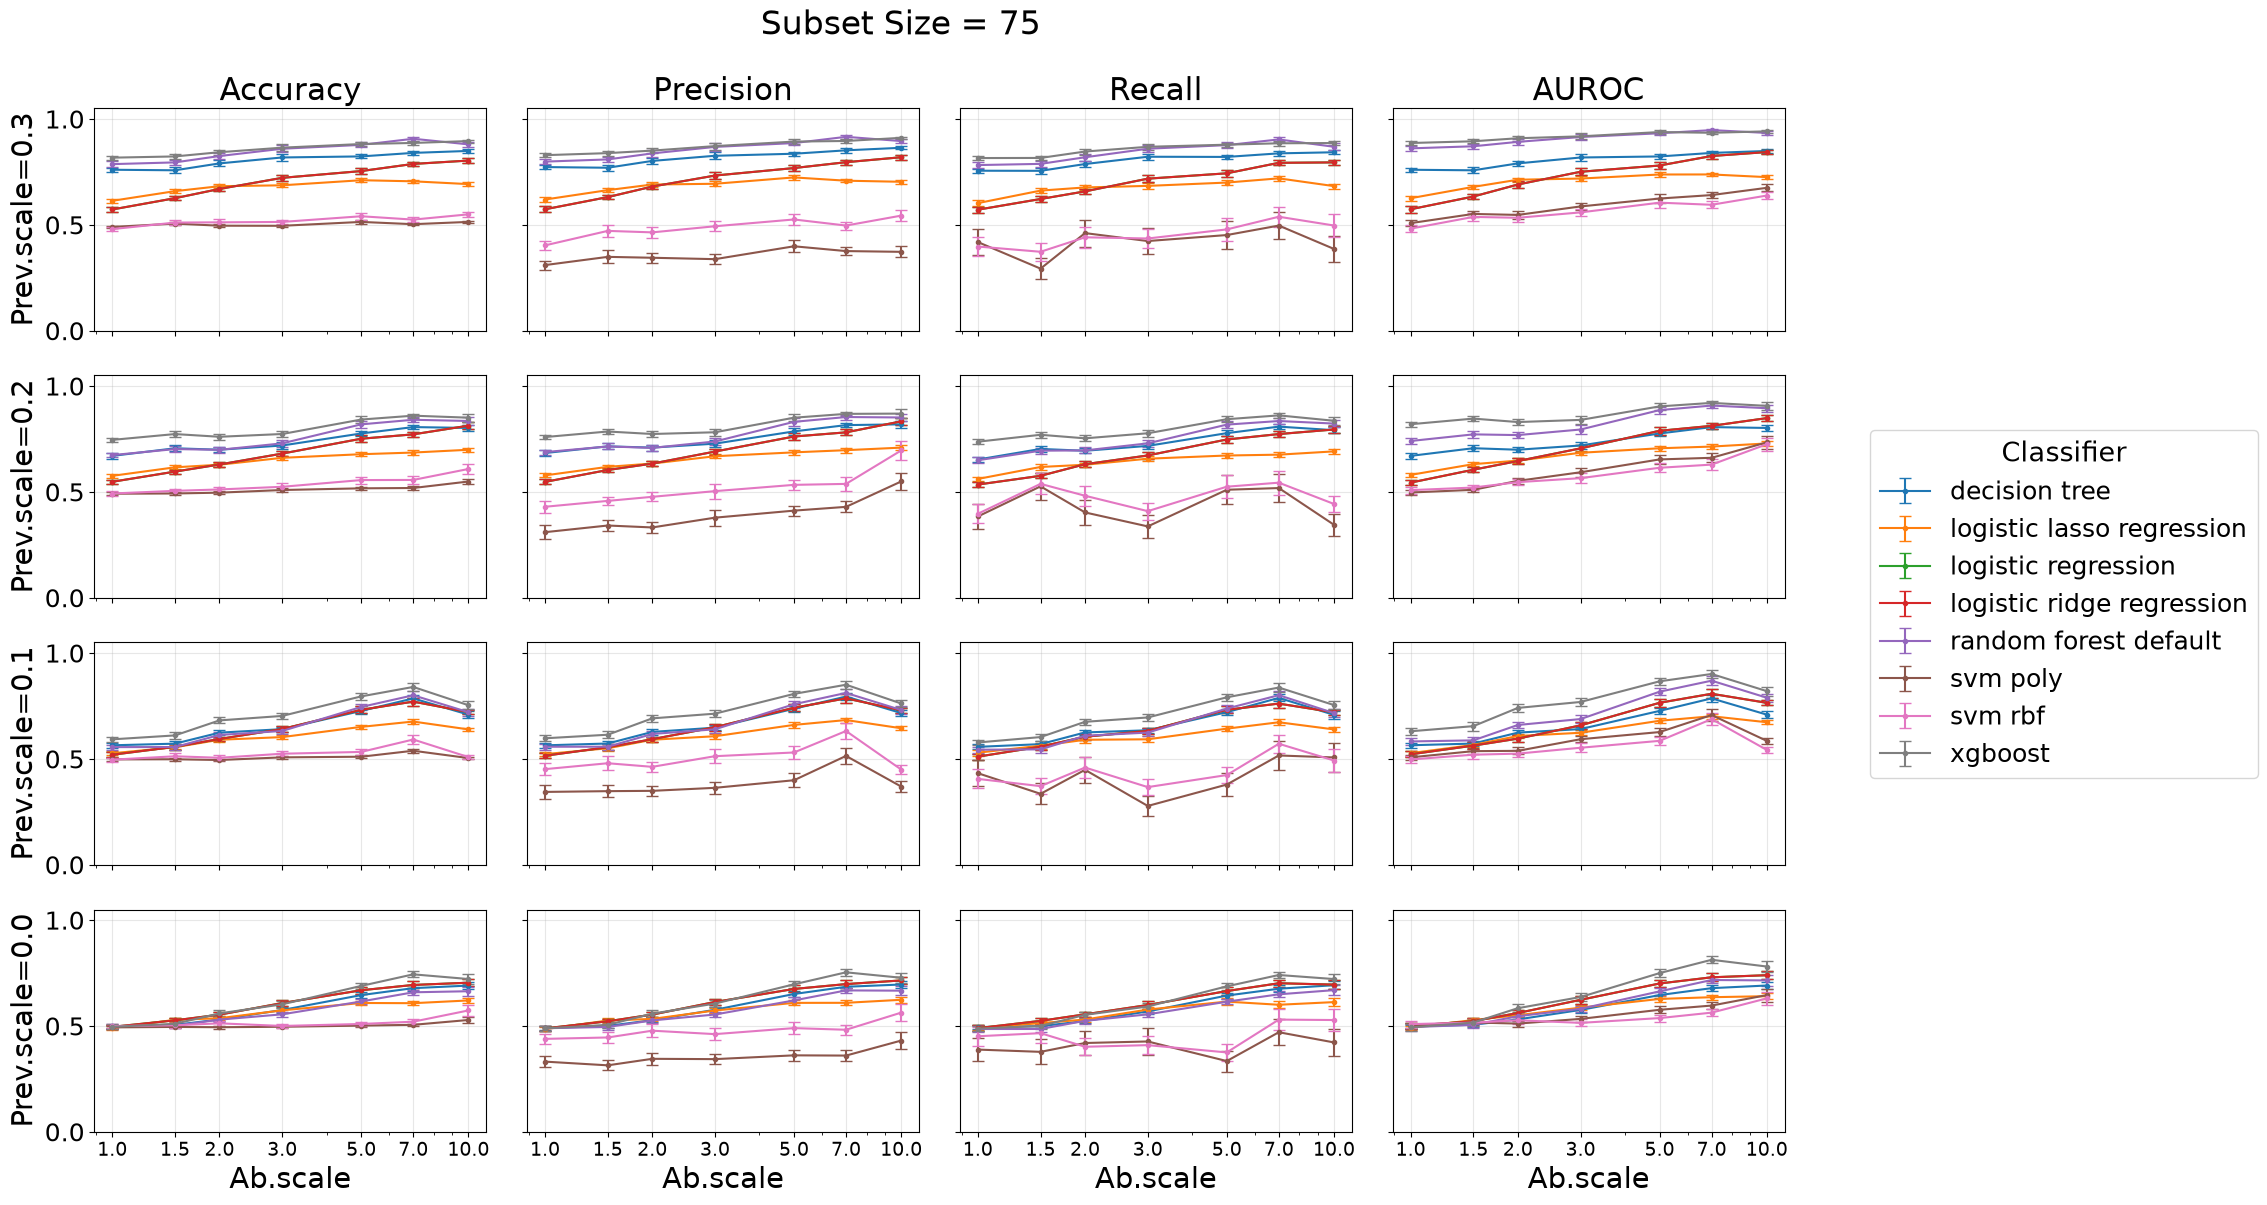

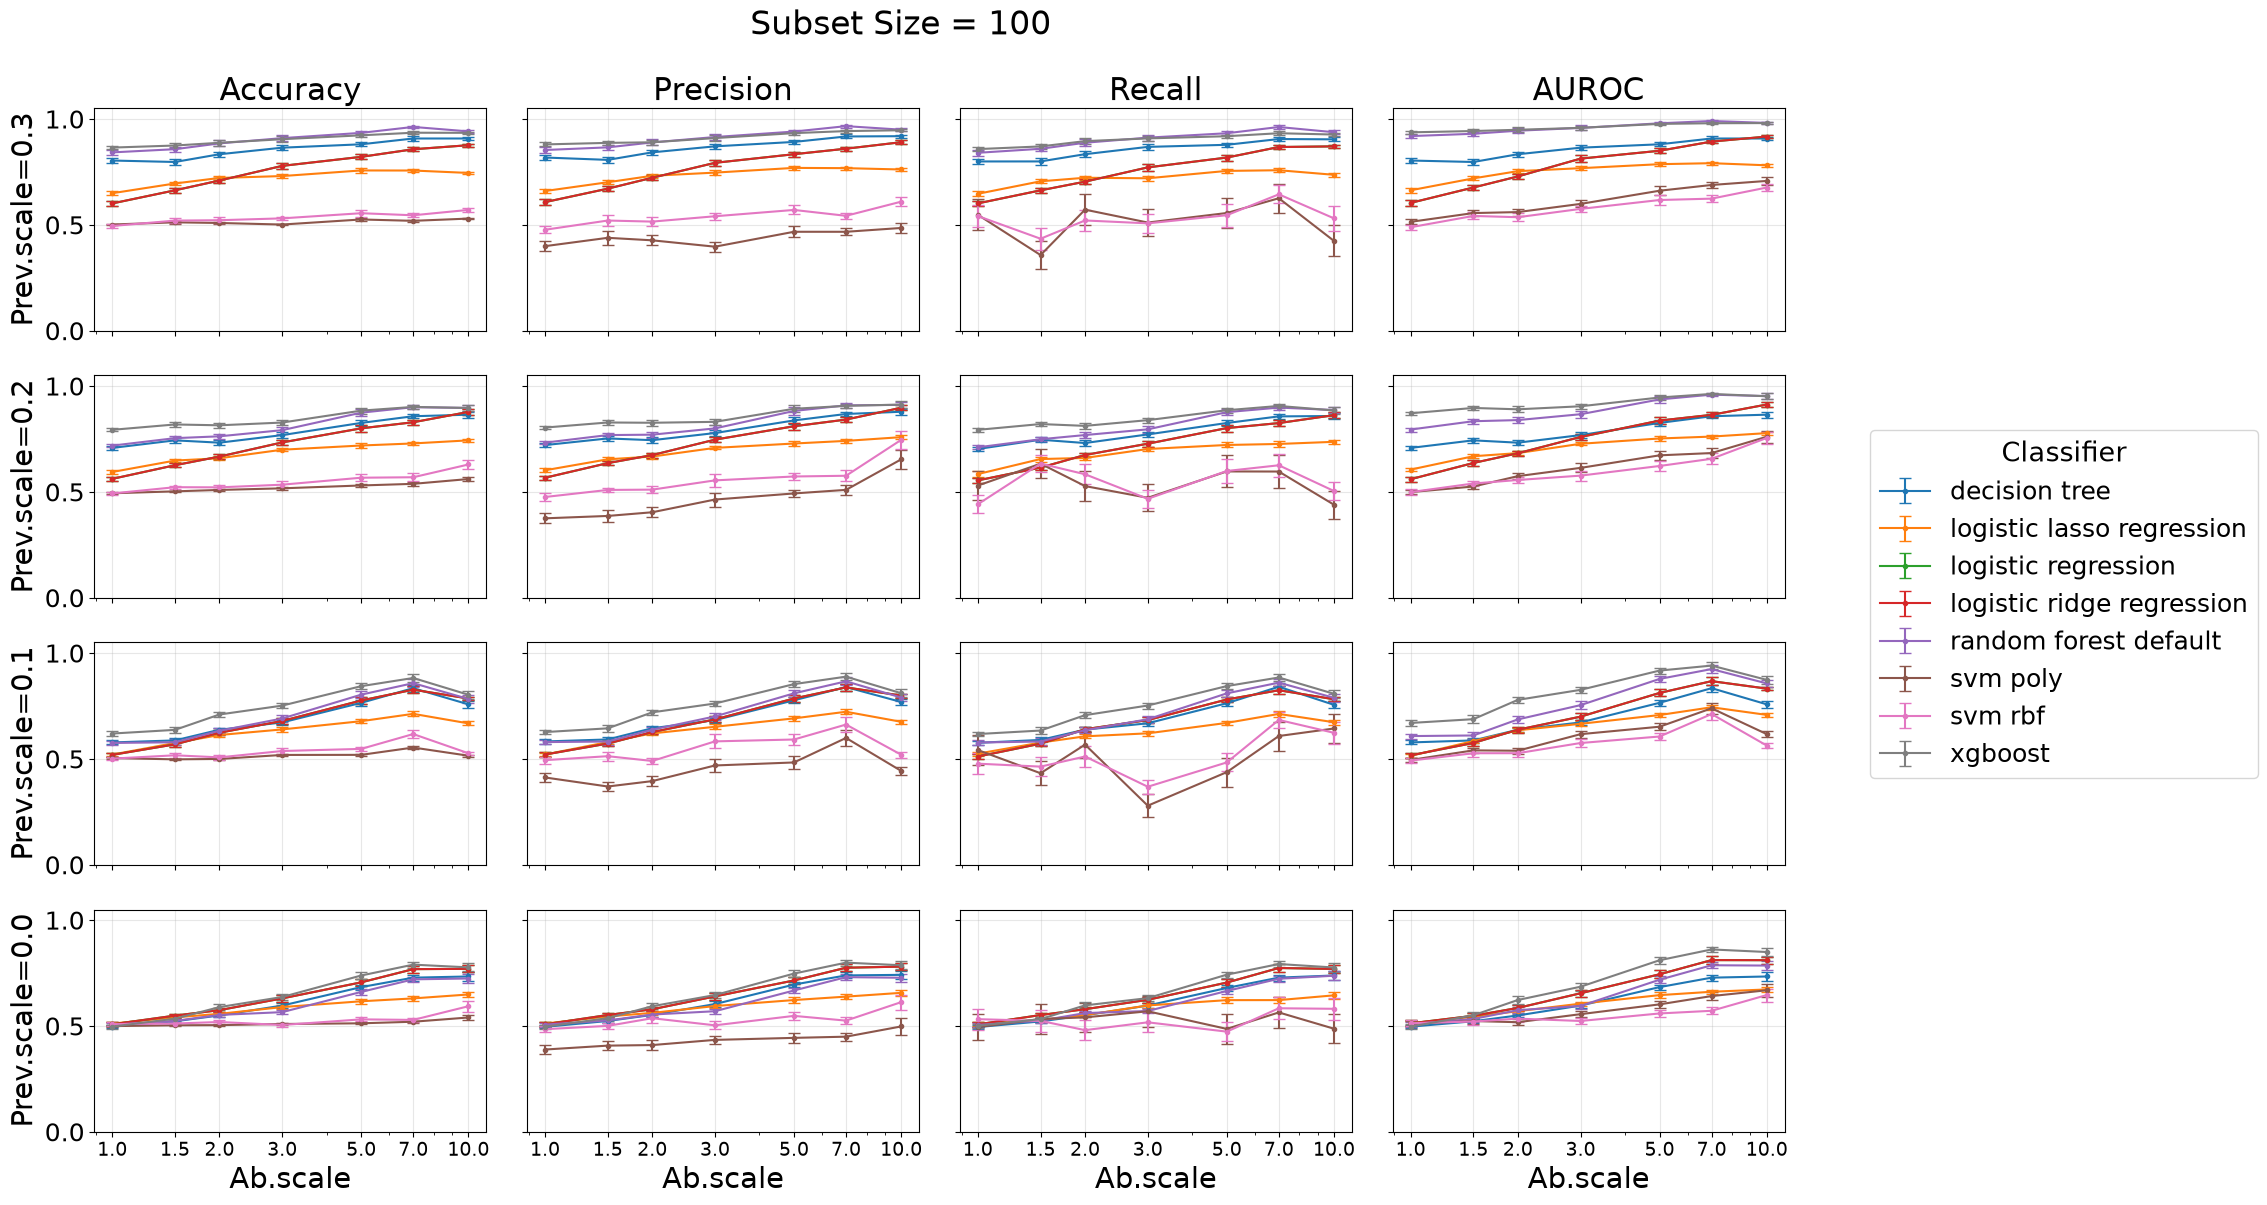

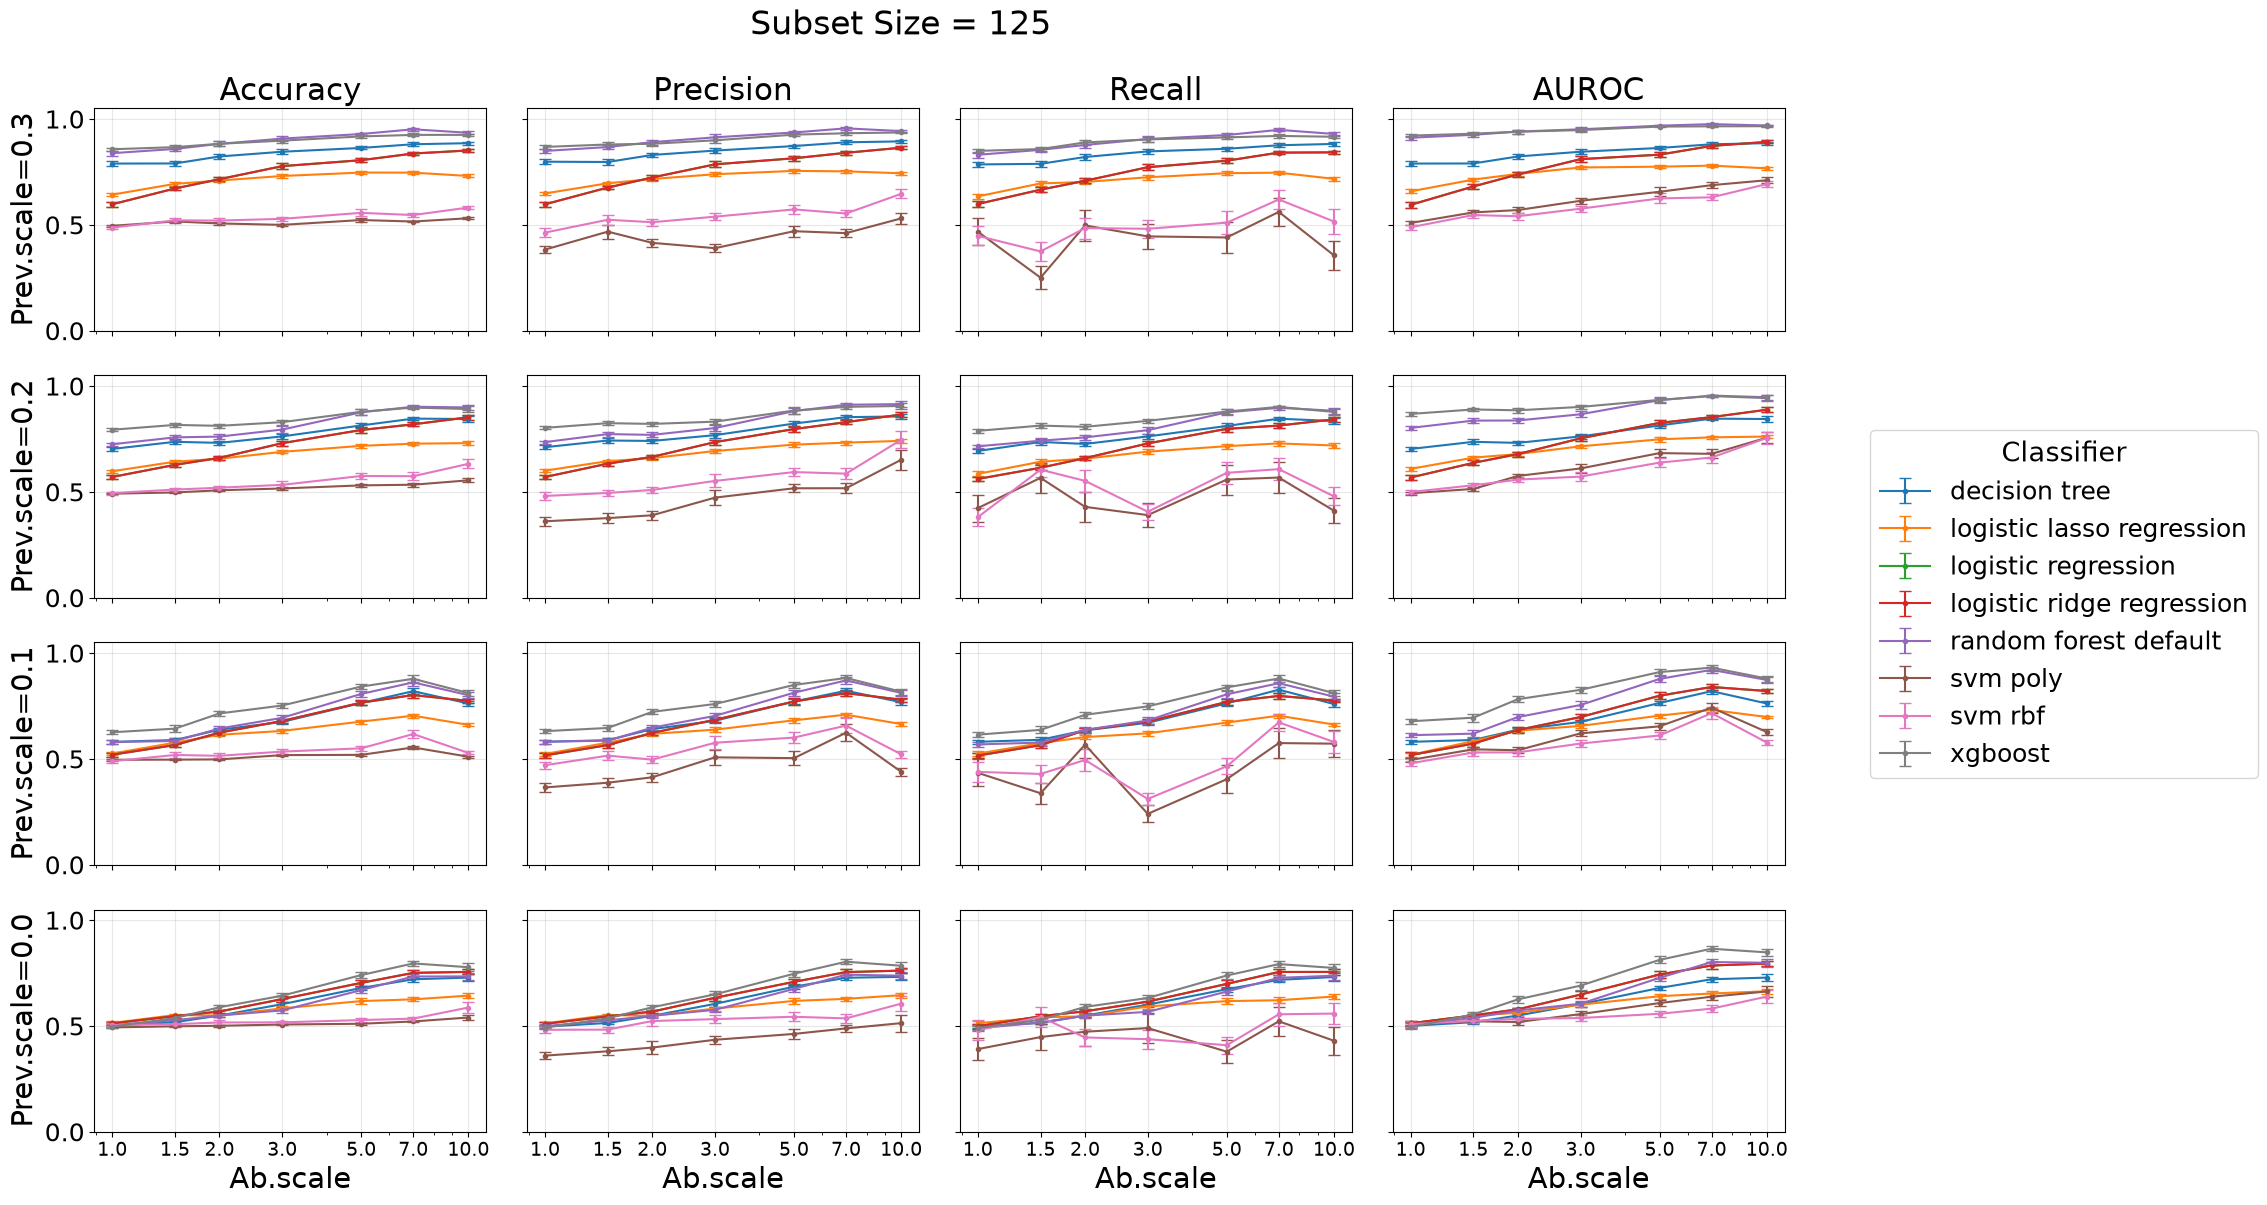

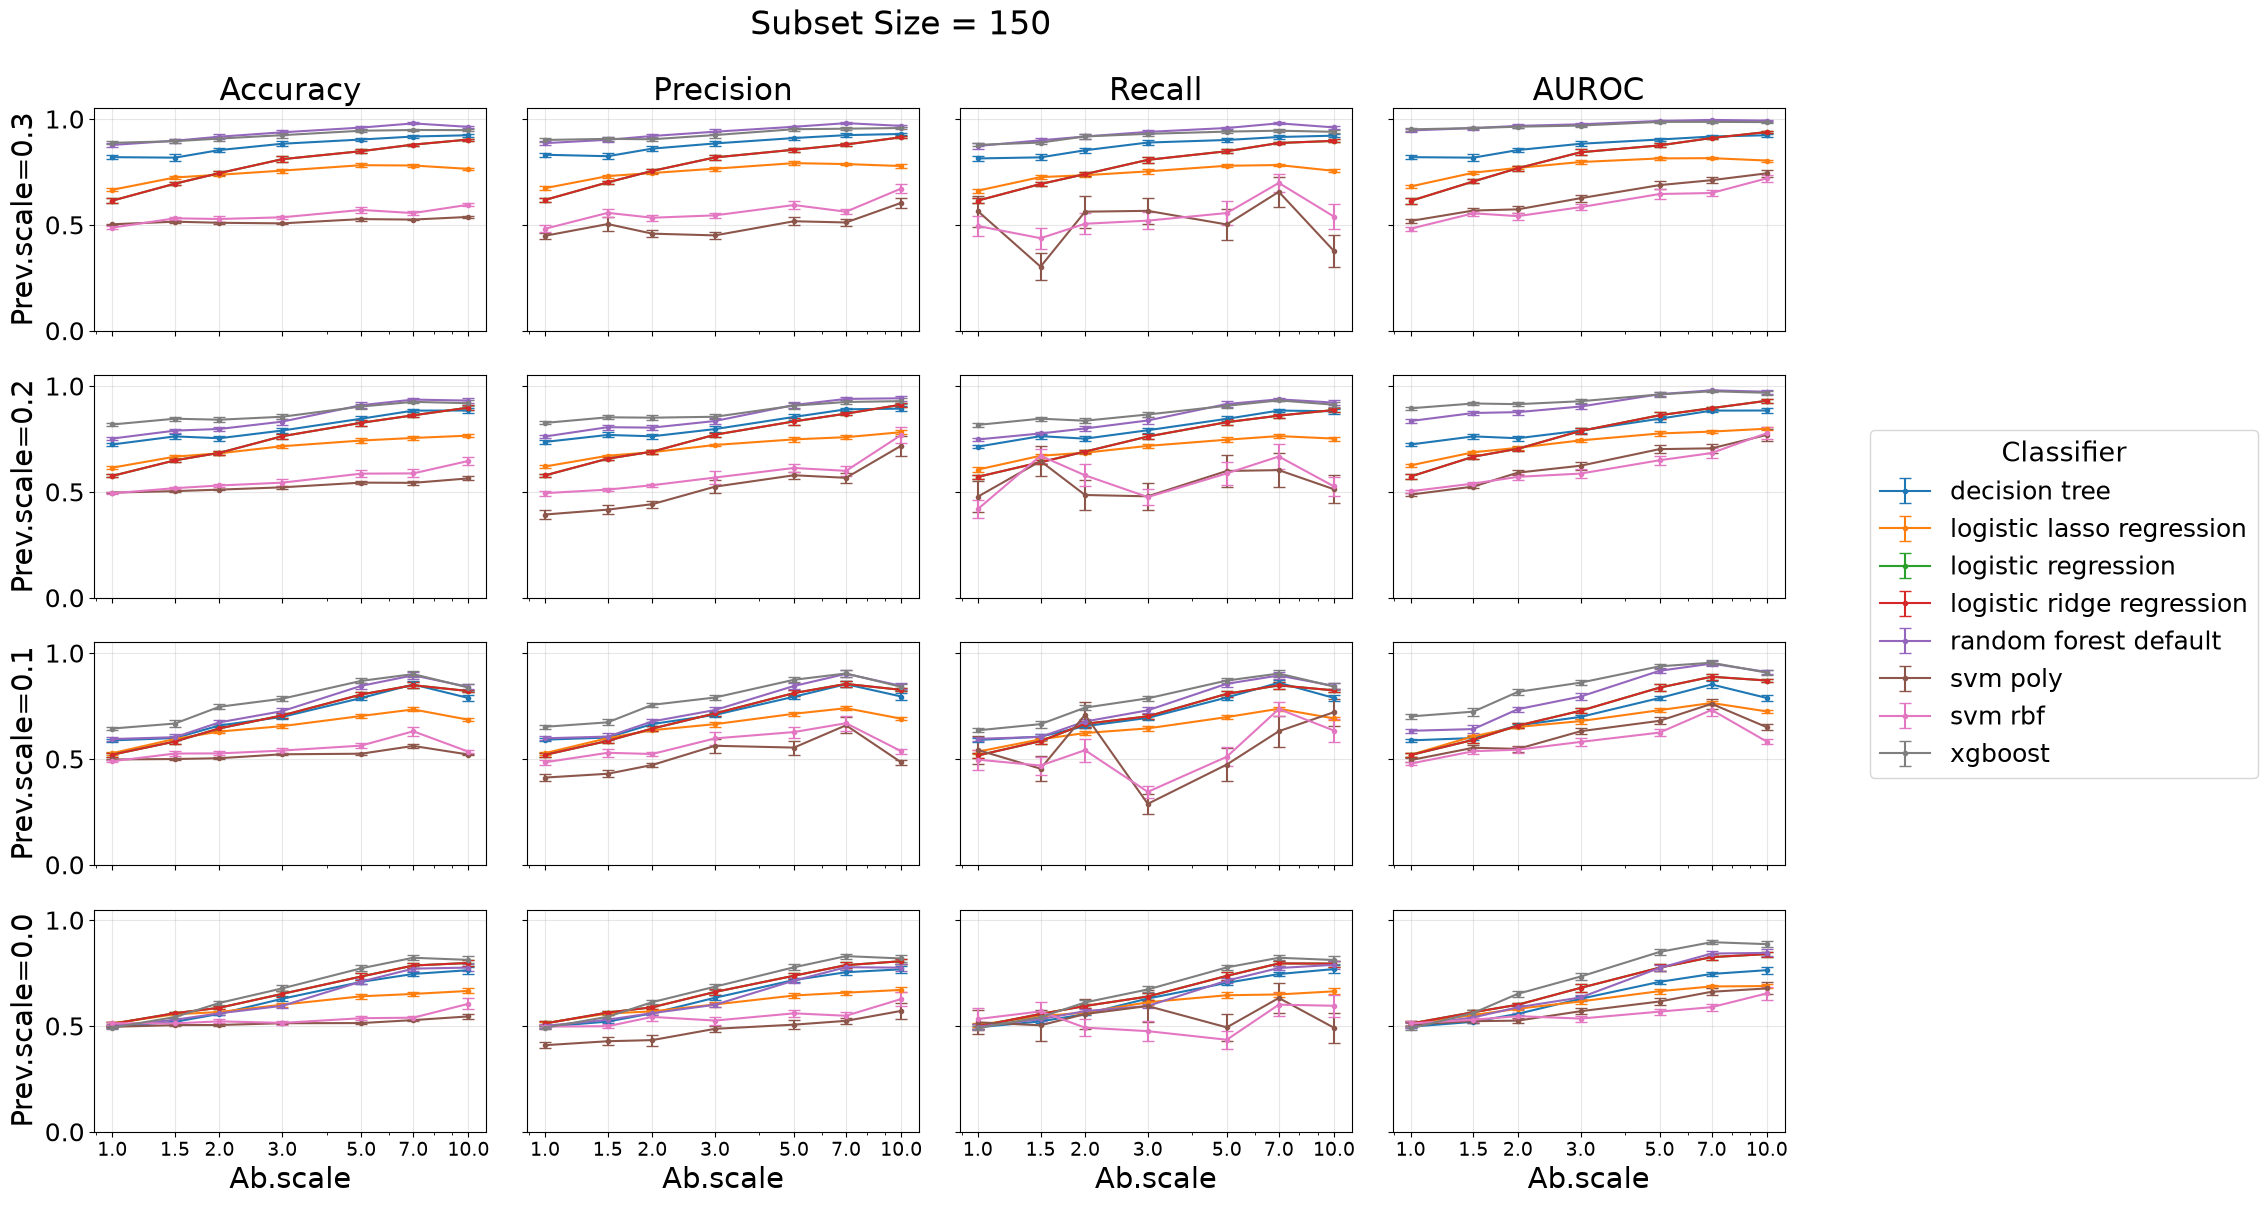

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter

def pretty_classifier(name):
    return str(name).replace("_", " ")

df = metric_summary.copy()

out_dir = Path("classification_plots") / f"{sim_name}" / "metrics_by_effect"
out_dir.mkdir(parents=True, exist_ok=True)

df.columns = [
    col[0] if (not isinstance(col, tuple) or col[1] == "") else f"{col[0]} {col[1]}"
    for col in df.columns.to_flat_index()
]

metric_cols = ["Accuracy", "Precision", "Recall", "AUROC"]

subset_sizes = sorted(df["Subset Size"].dropna().unique())
prev_scales = sorted(df["Prev.scale"].dropna().unique(), reverse=True)
ab_ticks = sorted(df["Ab.scale"].dropna().unique())
ab_labels = [str(t) for t in ab_ticks]

n_rows, n_cols = len(prev_scales), len(metric_cols)

f = 1.5
plot_style = {
    "font.size": 13*f,
    "axes.titlesize": 15*f,
    "axes.labelsize": 14*f,
    "xtick.labelsize": 9*f,
    "ytick.labelsize": 12*f,
    "legend.fontsize": 12*f,
    "legend.title_fontsize": 13*f,
    "figure.titlesize": 16*f,
}

with plt.rc_context(plot_style):
    for subset_size in subset_sizes:
        subset_df = df[df["Subset Size"] == subset_size]
        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(4.6 * n_cols, 3.1 * n_rows),
            sharex=True,
            sharey=True,
        )
        if n_rows == 1 and n_cols == 1:
            axes = np.array([[axes]])
        elif n_rows == 1:
            axes = np.array([axes])
        elif n_cols == 1:
            axes = np.array([[ax] for ax in axes])

        for row, prev_scale in enumerate(prev_scales):
            row_df = subset_df[subset_df["Prev.scale"] == prev_scale]
            for col, metric in enumerate(metric_cols):
                ax = axes[row, col]
                for classifier, clf_df in row_df.groupby("Classifier", sort=False):
                    clf_df = clf_df.sort_values("Ab.scale")
                    ax.errorbar(
                        clf_df["Ab.scale"],
                        clf_df[f"{metric} mean"],
                        yerr=2 * clf_df[f"{metric} sem"],
                        marker="o",
                        ms=3,
                        linewidth=1.5,
                        capsize=4,
                        label=pretty_classifier(classifier),
                    )
                ax.grid(True, alpha=0.3)
                ax.set_ylim(0, 1.05)
                ax.set_xscale("log")
                ax.xaxis.set_major_locator(FixedLocator(ab_ticks))
                ax.xaxis.set_major_formatter(FixedFormatter(ab_labels))
                ax.xaxis.set_minor_formatter(NullFormatter())

                if row == 0:
                    ax.set_title(metric)
                if col == 0:
                    ax.set_ylabel(f"Prev.scale={prev_scale}")
                if row == n_rows - 1:
                    ax.set_xlabel("Ab.scale")

        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(
            handles, labels,
            title="Classifier",
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
        )
        fig.suptitle(f"Subset Size = {int(subset_size)}")
        fig.tight_layout()
        for ax in axes.ravel():
            ax.xaxis.set_major_locator(FixedLocator(ab_ticks))
            ax.xaxis.set_major_formatter(FixedFormatter(ab_labels))
            ax.xaxis.set_minor_formatter(NullFormatter())
        plt.show()
        fig.savefig(out_dir / f"{subset_size}.png", dpi=200, bbox_inches="tight")